# Predicting the Brent–WTI Spread Using Oil Market Fundamentals

**Maria-Giulia Salvarani and Samuel Macé**  
*Machine Learning for Portfolio Management and Trading*

## 1. Context and economic intuition

### 1.1 Economic context

Brent and West Texas Intermediate (WTI) are two major crude oil price benchmarks. Both respond to global oil market conditions, but their prices also reflect differences in regional supply, refinery demand, storage, and access to international markets. In our data, WTI is priced at Cushing, Oklahoma, while Brent represents the European benchmark.

The relationship between the benchmarks has changed over time. The EIA documents how rising US and Canadian crude supply, together with transportation constraints at Cushing, contributed to a substantial WTI discount in the early 2010s. Subsequent infrastructure expansion improved connections with coastal refining markets [3]. The removal of US crude export restrictions in December 2015 further expanded access to overseas buyers [4]. These developments illustrate why a common global oil market can coexist with persistent regional price differences.

### 1.2 Economic intuition and research question

We define the spread in US dollars per barrel as:

$$
S_t = P_t^{Brent} - P_t^{WTI}.
$$

An increase means that Brent becomes more expensive relative to WTI. An accumulation of US crude inventories, for example, could indicate that local supply exceeds the amount absorbed by refineries or exports. If this puts greater downward pressure on WTI, the spread could widen. Stronger refinery demand or greater exports could instead absorb the surplus and support WTI. Changes in European supply and refining conditions may affect Brent differently.

These mechanisms motivate our research question: **do oil market fundamentals improve forecasts of the monthly change in the Brent–WTI spread compared with models using past prices alone?** We then ask whether the resulting forecasts improve a long–short trading strategy after transaction costs.

### 1.3 Related literature and our approach

Geyer-Klingeberg and Rathgeber (2021) study the WTI–Brent differential over 1995–2019 using an autoregressive distributed-lag model and structural-break analysis. They identify a major break in December 2010 and highlight inventory-related convenience yields, shipping costs, and financial-market activity among the spread determinants [1]. Their findings motivate examining storage conditions and allowing relationships to evolve over time. Our JODI stock measures are physical inventory observations, rather than direct measures of convenience yield.

Sifat, Zarei, and Ah Mand (2023) examine US and international demand, supply, and uncertainty factors over 1988–2020. Their analysis highlights changes in spread behaviour around the shale-oil expansion and the relevance of physical flows, including Canadian imports and pipeline activity [2]. This supports our interest in regional production, trade, and refinery conditions. It does not imply that every delayed monthly fundamental will provide additional forecasting information.

We extend this economic motivation to a compact machine-learning experiment: comparing price-only forecasts with regional and pooled JODI aggregates, followed by a common trading rule. Following the course workflow [5], the analysis links interpretable predictors to chronological forecasts, positions, risk, and transaction costs. We consistently define the spread as **Brent minus WTI**; directional statements from studies using the opposite convention must be reversed before comparison.

## 2. Data

The project combines crude oil prices from the US Energy Information Administration (EIA), obtained through FRED, with physical oil market fundamentals from the Joint Organisations Data Initiative (JODI).
All raw data are retrieved programmatically from their original online sources. Daily Brent and WTI prices are downloaded from FRED, while monthly crude oil fundamentals are obtained from the official JODI Oil database. No manually downloaded input datasets are required. The automated pipeline applies the same cleaning and transformation procedures whenever the notebook is executed.

### Oil prices

We use daily Brent and WTI spot prices, expressed in US dollars per barrel. These series describe the historical evolution of the benchmarks and allow us to construct the spread. The price series are available through FRED as [DCOILBRENTEU](https://fred.stlouisfed.org/series/DCOILBRENTEU) and [DCOILWTICO](https://fred.stlouisfed.org/series/DCOILWTICO).

### Oil market fundamentals

The [JODI Oil database](https://www.jodidata.org/oil/) provides monthly observations from 2002 onward. We retain six components of the crude oil balance:

| Variable | Description |
|---|---|
| Production | Domestic crude oil production |
| Closing inventories | Crude oil stocks held at the end of the month |
| Inventory changes | Changes in crude oil stocks during the month |
| Imports | Crude oil imported into an economy |
| Exports | Crude oil exported from an economy |
| Refinery intake | Crude oil entering refineries for processing |

These variables represent the supply, storage, trade, and refinery-demand mechanisms introduced above. Country coverage and regional aggregation are established during data preparation.

## 3. Forecasting objective

We aim to predict the monthly change in the Brent–WTI spread:

$$
\Delta S_{t+1} = S_{t+1} - S_t
$$

A positive value indicates that the spread widens over the following month, while a negative value indicates that it narrows.

Our economic intuition is that the geographical distribution of oil supply and demand matters for the relative prices of Brent and WTI. Fundamentals in markets closely connected to WTI may affect that benchmark more directly, while conditions in markets connected to Brent may have a different influence. Aggregating fundamentals across all available countries could capture broader oil market conditions, but may also conceal regional imbalances.

To examine whether these distinctions help forecast spread changes, we compare five information sets:

| Specification | Predictors |
|---|---|
| Prices only | Historical price and spread information |
| Prices + WTI-related fundamentals | Price predictors and aggregates for economies economically connected to WTI |
| Prices + Brent-related fundamentals | Price predictors and aggregates for economies economically connected to Brent |
| Prices + both regional blocks | Price predictors and the two groups of aggregates, kept separate |
| Prices + pooled fundamentals | Price predictors and aggregates across all countries retained from JODI |

The country groups are defined according to their economic connection to each benchmark and the availability and consistency of the data. The broad European group is a regional proxy, not the composition of the Brent benchmark itself.

For each group, physical quantities are aggregated across countries using consistent units before calculating growth rates or other transformations. This preserves the economic meaning of the variables while limiting the number of predictors.

These comparisons address two questions: whether fundamentals improve forecasts beyond past prices, and whether distinguishing between Brent-related and WTI-related conditions provides more information than pooling fundamentals across countries.

## 4. Data preparation


### 4.1 Imports and project paths


In [1]:
from pathlib import Path
from io import BytesIO
import pandas as pd
import requests
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd()
print(f"Project directory: {PROJECT_DIR}")

Project directory: /Users/samuelmace/Documents/brent-wti-ml-project


### 4.2 Spot prices

We retrieve daily Brent and WTI spot prices automatically from FRED, clean and align their observation dates, and visualize the resulting price series and spread.

In [2]:

def clean_eia_prices(start_date="2002-01-01"):
    """Download, clean and align daily Brent and WTI spot prices."""

    def load_price(series_id, name):
        url = "https://fred.stlouisfed.org/graph/fredgraph.csv"

        response = requests.get(
            url,
            params={
                "id": series_id,
                "cosd": start_date,
            },
            timeout=60,
        )
        response.raise_for_status()

        df = pd.read_csv(
            BytesIO(response.content),
            na_values=["."],
        )

        if len(df.columns) != 2:
            raise ValueError(
                f"{series_id}: expected two columns, "
                f"received {df.columns.tolist()}"
            )

        df.columns = ["date", name]
        df["date"] = pd.to_datetime(
            df["date"], errors="raise"
        )
        df[name] = pd.to_numeric(
            df[name], errors="raise"
        )

        if df["date"].isna().any():
            raise ValueError(f"{series_id}: missing dates")

        if df["date"].duplicated().any():
            raise ValueError(f"{series_id}: duplicate dates")

        return (
            df.dropna(subset=[name])
            .sort_values("date")
        )

    brent = load_price("DCOILBRENTEU", "Brent")
    wti = load_price("DCOILWTICO", "WTI")

    prices = brent.merge(
        wti,
        on="date",
        how="inner",
        validate="one_to_one",
    )

    if prices.empty:
        raise ValueError("No common Brent/WTI observations")

    return prices.sort_values("date").reset_index(drop=True)


In [3]:
prices = clean_eia_prices()

print(f"Observations: {len(prices):,}")
print(f"Period: {prices['date'].min():%Y-%m-%d} to "
      f"{prices['date'].max():%Y-%m-%d}")

print("\nMissing values after cleaning:")
print(prices.isna().sum())

prices.head()

Observations: 5,715
Period: 2002-01-02 to 2026-11-11

Missing values after cleaning:
date     0
Brent    0
WTI      0
dtype: int64


,date,Brent,WTI
0,2002-01-02,20.13,21.13
1,2002-01-04,21.20,21.47
2,2002-01-07,21.08,21.42
3,2002-01-09,20.21,20.32
4,2002-01-10,19.71,20.48


In [4]:
import matplotlib.pyplot as plt

def plot_prices_and_spread(prices):
    """Plot Brent and WTI prices and their spread."""
    data = prices.sort_values("date")
    spread = data["Brent"] - data["WTI"]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    axes[0].plot(
        data["date"], data["Brent"], label="Brent", linewidth=1
    )
    axes[0].plot(
        data["date"], data["WTI"], label="WTI", linewidth=1
    )
    axes[0].set_title("Brent and WTI spot prices")
    axes[0].set_ylabel("USD / barrel")
    axes[0].legend(frameon=False)

    axes[1].plot(data["date"], spread, color="teal", linewidth=1)
    axes[1].axhline(
        0, color="grey", linewidth=0.8, linestyle="--"
    )
    axes[1].set_title("Brent–WTI spread")
    axes[1].set_ylabel("USD / barrel")
    axes[1].set_xlabel("Date")

    for ax in axes:
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()
    plt.show()


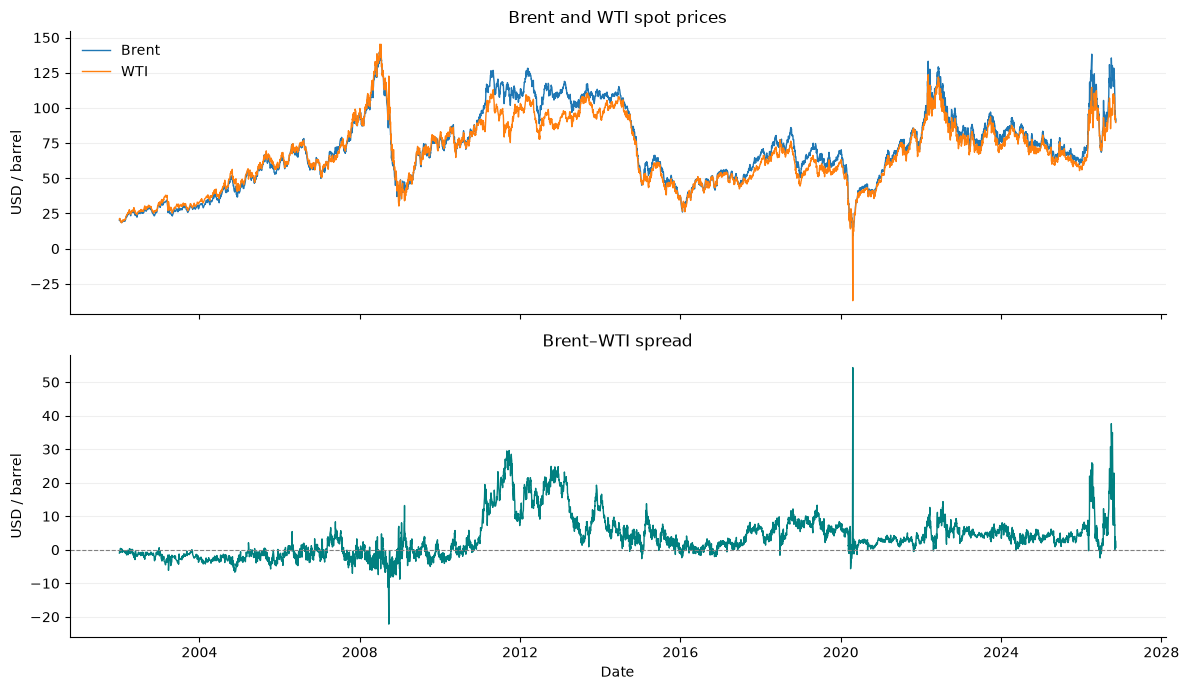

In [5]:
plot_prices_and_spread(prices)

### 4.3 Monthly price variables

We work at a monthly frequency to match the JODI fundamentals. For each month, we retain the last common Brent and WTI price observation and calculate the spread.

Since monthly sampling leaves relatively few observations, we use a small set of price-based predictors to limit model complexity. These capture the spread's current level, latest monthly change, six-month trend, and twelve-month variability.

The forecasting target is the change in the spread between the current and following month-end observations.

In [6]:
import pandas as pd

def build_monthly_price_features(prices):
    """Construct month-end prices, four predictors and next-month target."""
    df = prices[["date", "Brent", "WTI"]].copy()
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date")

    monthly = (
        df.groupby(df["date"].dt.to_period("M"))
        .tail(1)
        .rename(columns={"date": "price_date"})
        .reset_index(drop=True)
    )

    monthly["date"] = (
        monthly["price_date"].dt.to_period("M").dt.to_timestamp("M")
    )

    current_month = pd.Timestamp.today().to_period("M")
    monthly = monthly.loc[
        monthly["date"].dt.to_period("M") < current_month
    ]

    monthly = monthly.set_index("date").asfreq("ME")

    monthly["spread"] = monthly["Brent"] - monthly["WTI"]
    monthly["spread_change"] = monthly["spread"].diff()
    monthly["spread_change_mean_6"] = (
        monthly["spread_change"].rolling(6).mean()
    )
    monthly["spread_change_vol_12"] = (
        monthly["spread_change"].rolling(12).std()
    )
    monthly["target_spread_change"] = (
        monthly["spread"].shift(-1) - monthly["spread"]
    )

    return monthly.reset_index()

In [7]:
PRICE_FEATURES = [
    "spread",
    "spread_change",
    "spread_change_mean_6",
    "spread_change_vol_12",
]

monthly_prices = build_monthly_price_features(prices)

print(f"Monthly observations: {len(monthly_prices):,}")
display(
    monthly_prices[
        ["date", "price_date"] + PRICE_FEATURES + ["target_spread_change"]
    ].tail()
)


Monthly observations: 298


,date,price_date,spread,spread_change,spread_change_mean_6,spread_change_vol_12,target_spread_change
293,2026-06-30,2026-06-30,-0.10,-1.82,-0.698333,7.865285,10.89
294,2026-07-31,2026-07-31,10.79,10.89,0.506667,8.490336,-5.61
295,2026-08-31,2026-08-28,5.18,-5.61,0.136667,8.681112,13.55
296,2026-09-30,2026-09-30,18.73,13.55,-0.850000,9.507757,-6.14
297,2026-10-31,2026-10-30,12.59,-6.14,-0.501667,9.712381,NaN


### 4.4 JODI fundamentals

We retrieve the JODI Oil Primary annual datasets programmatically from the official JODI website, starting in 2002. The CSV files are downloaded directly into memory, eliminating the need for manually downloaded input files.

The extraction function applies consistent filtering, data-type conversion, and validation procedures. This allows the data preparation pipeline to be rerun when new JODI observations or historical revisions become available.

In [8]:
JODI_BASE_URL = (
    "https://www.jodidata.org/_resources/files/"
    "downloads/oil-data/annual-csv/primary"
)

JODI_START_YEAR = 2002
JODI_END_YEAR = pd.Timestamp.today().year

print(
    f"JODI Primary extraction: "
    f"{JODI_START_YEAR}-{JODI_END_YEAR}"
)

JODI Primary extraction: 2002-2026


We retain crude oil observations for production, inventories, inventory changes, imports, exports, and refinery intake. Stocks and stock changes are expressed in thousand barrels, while production, trade flows, and refinery intake are expressed in thousand barrels per day. Non-numeric entries are treated as missing values.

In [9]:

def clean_jodi_oil(start_year=2002, end_year=None):
    """
    Download JODI Primary annual CSV files in memory,
    then apply the original notebook's cleaning rules.
    """

    if end_year is None:
        end_year = pd.Timestamp.today().year

    units = {
        "CLOSTLV": "KBBL",
        "STOCKCH": "KBBL",
        "INDPROD": "KBD",
        "TOTIMPSB": "KBD",
        "TOTEXPSB": "KBD",
        "REFINOBS": "KBD",
    }

    base_url = (
        "https://www.jodidata.org/_resources/files/"
        "downloads/oil-data/annual-csv/primary"
    )

    session = requests.Session()
    session.headers.update({
        "User-Agent": "Academic-JODI-Research/1.0"
    })

    frames = []

    for year in range(start_year, end_year + 1):

        filenames = [
            f"{year}.csv",
            f"primaryyear{year}.csv",
        ]

        print(f"Downloading JODI Primary {year}...")

        response = None

        for filename in filenames:
            url = f"{base_url}/{filename}"

            candidate = session.get(url, timeout=120)

            if candidate.status_code == 404:
                continue

            candidate.raise_for_status()
            response = candidate
            break

        if response is None:
            raise FileNotFoundError(
                f"No JODI Primary file found for {year}"
            )

        df = pd.read_csv(BytesIO(response.content))

        required = {
            "ENERGY_PRODUCT",
            "UNIT_MEASURE",
            "FLOW_BREAKDOWN",
            "REF_AREA",
            "TIME_PERIOD",
            "OBS_VALUE",
            "ASSESSMENT_CODE",
        }

        missing = required - set(df.columns)
        if missing:
            raise ValueError(
                f"JODI {year}: missing columns {missing}"
            )

        keep = (
            df["ENERGY_PRODUCT"].eq("CRUDEOIL")
            & df["UNIT_MEASURE"].eq(
                df["FLOW_BREAKDOWN"].map(units)
            )
        )

        frames.append(df.loc[keep].copy())

    if not frames:
        raise ValueError("No JODI data downloaded")

    jodi = (
        pd.concat(frames, ignore_index=True)
        .drop_duplicates()
    )

    jodi["TIME_PERIOD"] = pd.to_datetime(
        jodi["TIME_PERIOD"],
        format="%Y-%m",
        errors="raise",
    )

    jodi["OBS_VALUE"] = pd.to_numeric(
        jodi["OBS_VALUE"],
        errors="coerce",
    )

    jodi = jodi.rename(
        columns={
            "REF_AREA": "country",
            "TIME_PERIOD": "date",
            "FLOW_BREAKDOWN": "variable",
            "UNIT_MEASURE": "unit",
            "OBS_VALUE": "value",
            "ASSESSMENT_CODE": "assessment_code",
        }
    )

    keys = ["country", "date", "variable"]

    if jodi.duplicated(keys).any():
        raise ValueError(
            "Multiple records found for the same "
            "country, month and variable."
        )

    return (
        jodi[
            [
                "country",
                "date",
                "variable",
                "unit",
                "value",
                "assessment_code",
            ]
        ]
        .sort_values(keys)
        .reset_index(drop=True)
    )


In [10]:
jodi = clean_jodi_oil()

print(f"Observations: {len(jodi):,}")
print(f"Countries / areas: {jodi['country'].nunique()}")
print(f"Period: {jodi['date'].min():%Y-%m} to "
      f"{jodi['date'].max():%Y-%m}")

print("\nMissing values by variable:")
display(
    jodi.groupby("variable")["value"]
    .agg(observations="size", missing=lambda s: s.isna().sum())
)

jodi.head()

Observations: 209,568
Countries / areas: 118
Period: 2002-01 to 2026-08

Missing values by variable:


,observations,missing
variable,,
CLOSTLV,34928,12895
INDPROD,34928,10220
REFINOBS,34928,10680
STOCKCH,34928,12131
TOTEXPSB,34928,10823
TOTIMPSB,34928,10570


,country,date,variable,unit,value,assessment_code
0,AE,2002-01-01,CLOSTLV,KBBL,NaN,3
1,AE,2002-01-01,INDPROD,KBD,1955.0,1
2,AE,2002-01-01,REFINOBS,KBD,202.0,3
3,AE,2002-01-01,STOCKCH,KBBL,NaN,3
4,AE,2002-01-01,TOTEXPSB,KBD,1860.0,3


### 4.5 Country selection and aggregation

For each variable, we retain countries with observations available in every month of the sample period. These fixed country pools form the basis of the regional and pooled aggregates.


In [11]:
JODI_SAMPLE_END = pd.Timestamp("2025-12-01")

jodi = jodi.loc[
    jodi["date"] <= JODI_SAMPLE_END
].copy()

months = pd.date_range(
    start=jodi["date"].min(),
    end=JODI_SAMPLE_END,
    freq="MS",
)

complete_country_pools = {}

JODI_FLOWS = [
    "CLOSTLV",   # Closing inventories
    "STOCKCH",   # Inventory changes
    "INDPROD",   # Production
    "TOTIMPSB",  # Imports
    "TOTEXPSB",  # Exports
    "REFINOBS",  # Refinery intake
]

for variable in JODI_FLOWS:
    panel = (
        jodi.loc[jodi["variable"].eq(variable)]
        .pivot(index="date", columns="country", values="value")
        .reindex(months)
    )

    complete_countries = panel.columns[
        panel.notna().all(axis=0)
    ].tolist()

    complete_country_pools[variable] = complete_countries

    print(f"{variable}: {len(complete_countries)} countries")
    print(", ".join(complete_countries))
    print()

CLOSTLV: 41 countries
AT, AU, AZ, BE, BN, CA, CH, CL, CZ, DE, DK, EE, ES, FI, FR, GB, GR, HU, IE, IS, IT, JP, KR, LU, LV, MX, NG, NL, NO, NZ, PL, PT, SA, SE, SI, SK, TH, TR, TW, US, UY

STOCKCH: 45 countries
AT, AU, BE, BG, BN, CA, CH, CL, CY, CZ, DE, DK, EE, ES, FI, FR, GB, GR, HR, HU, IE, IS, IT, JP, KR, LT, LU, LV, MX, NG, NL, NO, NZ, PL, PT, RO, SA, SE, SI, SK, TH, TR, TW, US, UY

INDPROD: 43 countries
AT, AU, AZ, BE, BN, CA, CH, CL, CN, CZ, DE, DK, EE, ES, FI, FR, GB, GR, HU, IE, IN, IS, IT, JP, KR, LU, LV, MX, NG, NL, NO, NZ, PL, PT, SA, SE, SI, SK, TH, TR, TW, US, VE

TOTIMPSB: 43 countries
AT, AU, BE, BN, CA, CH, CL, CN, CZ, DE, DK, EE, ES, FI, FR, GB, GR, HU, IE, IN, IS, IT, JP, KR, LU, LV, MX, NG, NL, NO, NZ, PL, PT, SA, SE, SG, SI, SK, TH, TR, TW, US, UY

TOTEXPSB: 39 countries
AT, AU, AZ, BE, BN, CA, CH, CL, CZ, DE, DK, EE, ES, FI, FR, GB, GR, HU, IE, IS, IT, JP, KR, LU, LV, MX, NG, NL, NO, NZ, PL, PT, SA, SE, SI, SK, TH, TR, US

REFINOBS: 42 countries
AT, AU, AZ, BE, BN, C

The WTI-related group initially contains the United States and Canada, while the Brent-related group initially includes selected European countries, covering North Sea producers and European refining, storage, and trading markets.

Countries with incomplete observations for any of the six JODI variables over the selected sample period are automatically excluded from their respective regional groups. The resulting country membership is held fixed over time.

For each variable, the pooled group contains all countries in its complete-country pool. Its geographical coverage may therefore differ across variables.

Physical quantities are summed within each group using consistent units.


In [13]:
BENCHMARK_COUNTRIES = {
    "WTI": ["US", "CA"],
    "Brent": [
        "AT",  # Austria
        "BE",  # Belgium
        "CH",  # Switzerland
        "CZ",  # Czechia
        "DE",  # Germany
        "DK",  # Denmark
        "EE",  # Estonia
        "ES",  # Spain
        "FI",  # Finland
        "FR",  # France
        "GB",  # United Kingdom
        "HU",  # Hungary
        "IE",  # Ireland
        "IS",  # Iceland
        "IT",  # Italy
        "LU",  # Luxembourg
        "LV",  # Latvia
        "NL",  # Netherlands
        "NO",  # Norway
        "PL",  # Poland
        "PT",  # Portugal
        "SE",  # Sweden
        "SI",  # Slovenia
        "SK",  # Slovakia
    ],
}

# Retain only countries with complete observations
# for all six JODI variables over the sample period.
for benchmark, countries in BENCHMARK_COUNTRIES.items():

    valid_countries = set(countries)

    for variable in JODI_FLOWS:
        valid_countries &= set(complete_country_pools[variable])

    removed_countries = set(countries) - valid_countries

    if removed_countries:
        print(
            f"{benchmark}: removing incomplete countries "
            f"{sorted(removed_countries)}"
        )

    BENCHMARK_COUNTRIES[benchmark] = [
        country for country in countries
        if country in valid_countries
    ]

    print(
        f"{benchmark}: "
        f"{len(BENCHMARK_COUNTRIES[benchmark])} valid countries"
    )

for benchmark, countries in BENCHMARK_COUNTRIES.items():
    if not countries:
        raise ValueError(
            f"{benchmark}: no countries remaining "
            "after completeness filtering."
        )

WTI: 2 valid countries
Brent: 24 valid countries


In [15]:
def build_jodi_aggregates(
    jodi,
    benchmark_countries,
    complete_country_pools,
    flows,
):
    """Sum JODI fundamentals over fixed regional and pooled country groups."""
    months = pd.date_range(
        start=jodi["date"].min(),
        end=jodi["date"].max(),
        freq="MS",
    )
    dataset = pd.DataFrame(index=months)
    dataset.index.name = "date"

    for variable in flows:
        panel = (
            jodi.loc[jodi["variable"].eq(variable)]
            .pivot(index="date", columns="country", values="value")
            .reindex(months)
        )

        groups = {
            **benchmark_countries,
            "Pooled": complete_country_pools[variable],
        }

        for group, countries in groups.items():
            if not countries:
                raise ValueError(f"No countries selected: {group}, {variable}")

            selected = panel.reindex(columns=countries)

            if selected.isna().any().any():
                raise ValueError(
                    f"Missing observations: {group}, {variable}"
                )

            dataset[f"{group}_{variable}"] = selected.sum(
                axis=1, min_count=len(countries)
            )

    return dataset.reset_index()


In [16]:
jodi_dataset = build_jodi_aggregates(
    jodi,
    BENCHMARK_COUNTRIES,
    complete_country_pools,
    JODI_FLOWS,
)

print(f"Monthly observations: {len(jodi_dataset):,}")
print(f"Fundamental variables: {jodi_dataset.shape[1] - 1}")
display(jodi_dataset.head())

Monthly observations: 288
Fundamental variables: 18


,date,WTI_CLOSTLV,Brent_CLOSTLV,Pooled_CLOSTLV,WTI_STOCKCH,Brent_STOCKCH,Pooled_STOCKCH,WTI_INDPROD,Brent_INDPROD,Pooled_INDPROD,WTI_TOTIMPSB,Brent_TOTIMPSB,Pooled_TOTIMPSB,WTI_TOTEXPSB,Brent_TOTEXPSB,Pooled_TOTEXPSB,WTI_REFINOBS,Brent_REFINOBS,Pooled_REFINOBS
0,2002-01-01,829112.33,415452.65,2063956.453,3705.22,17626.09,17776.792,7539.2812,6285.7794,34693.1417,9564.4678,11221.8382,33712.7774,1049.4510,4399.0877,15390.6747,16059.8994,12581.3307,47749.4653
1,2002-02-01,845489.28,418492.65,2077312.808,16376.95,3040.00,14151.549,7639.4321,6246.2652,34307.1582,9681.1271,11653.7692,34421.1855,1106.2522,5190.9526,15884.7414,15867.4321,12468.2899,48055.3944
2,2002-03-01,853494.32,395943.70,2076479.376,8005.04,-22548.95,-1878.874,7672.8929,5775.3235,33851.3708,9669.9794,10474.0644,33700.0560,1114.9496,4969.2917,15674.4095,16047.2987,12044.8021,47342.2864
3,2002-04-01,857007.69,400386.62,2073303.782,3513.37,4442.92,-2753.040,7680.7447,6272.0832,33816.8962,10129.1747,10958.3029,33918.1582,1141.8620,5230.8909,16123.1987,16723.9214,11921.4960,47855.0471
4,2002-05-01,861051.90,410723.75,2082933.426,4044.21,10337.13,9557.360,7721.9523,6118.5800,33797.0079,10093.6304,11140.9682,33635.5192,1169.1800,4913.6613,15804.2295,16806.5975,11653.5265,47357.3226


### 4.6 Combined monthly dataset

We combine the monthly price variables with the regional and pooled JODI aggregates. Fundamentals are matched to a decision month using an assumed two-month publication lag.

Each row contains the price predictors, the available fundamentals, and the following month's spread change.

In [17]:
def build_model_dataset(monthly_prices, jodi_dataset, jodi_lag=2):

    """Combine monthly prices with publication-lagged JODI aggregates."""
    fundamentals = jodi_dataset.rename(
        columns={"date": "jodi_reference_month"}
    ).copy()

    fundamentals["date"] = (
        fundamentals["jodi_reference_month"].dt.to_period("M") + jodi_lag
    ).dt.to_timestamp("M")

    dataset = monthly_prices.merge(
        fundamentals,
        on="date",
        how="inner",
        validate="one_to_one",
    )

    # Remove rows without complete predictors or an observed target
    dataset = (
        dataset.dropna()
        .sort_values("date")
        .reset_index(drop=True)
    )

    if dataset.empty:
        raise ValueError("No complete observations after merging.")

    return dataset

In [18]:
model_data = build_model_dataset(
    monthly_prices,
    jodi_dataset,
    jodi_lag=2,
)

print(f"Observations: {len(model_data):,}")
print(f"Period: {model_data['date'].min():%Y-%m} "
      f"to {model_data['date'].max():%Y-%m}")

display(model_data.head())

Observations: 278
Period: 2003-01 to 2026-02


,date,price_date,Brent,WTI,spread,spread_change,spread_change_mean_6,spread_change_vol_12,target_spread_change,jodi_reference_month,...,Pooled_INDPROD,WTI_TOTIMPSB,Brent_TOTIMPSB,Pooled_TOTIMPSB,WTI_TOTEXPSB,Brent_TOTEXPSB,Pooled_TOTEXPSB,WTI_REFINOBS,Brent_REFINOBS,Pooled_REFINOBS
0,2003-01-31,2003-01-31,31.57,33.51,-1.94,-2.55,-0.200000,1.261945,-2.56,2002-11-01,...,34560.1511,10481.2713,11213.2144,35260.3752,1272.9260,5282.9459,16423.1540,16698.5953,12727.3750,49176.0304
1,2003-02-28,2003-02-26,33.46,37.96,-4.50,-2.56,-0.463333,1.447632,-1.64,2002-12-01,...,32208.5205,9613.5200,11250.3055,34595.3446,1106.5703,5147.8887,16245.0334,16480.1697,12764.4138,49078.3670
2,2003-03-31,2003-03-25,27.28,33.42,-6.14,-1.64,-0.776667,1.488950,4.05,2003-01-01,...,33053.8300,9508.2503,11027.6016,34801.7038,1135.1807,4327.6733,15857.0488,15944.2117,12478.6893,48814.1814
3,2003-04-30,2003-04-29,23.23,25.32,-2.09,4.05,-0.070000,1.967174,-0.67,2003-02-01,...,34435.0058,9309.4136,11205.9396,35095.2466,1084.1321,5085.0054,17154.7359,15949.0371,12677.5253,49413.4178
4,2003-05-31,2003-05-29,26.39,29.15,-2.76,-0.67,-0.100000,1.972416,1.49,2003-03-01,...,35426.3913,10250.6200,12085.8325,35996.7832,1327.3471,4346.4100,16724.6375,16349.2271,12550.4467,49228.3130


### 4.7 Monthly spread changes

Before defining the forecasting experiment, we examine the monthly spread changes we aim to predict. Their evolution and distribution describe the typical size of movements, the presence of extreme observations, and differences in variability over time.

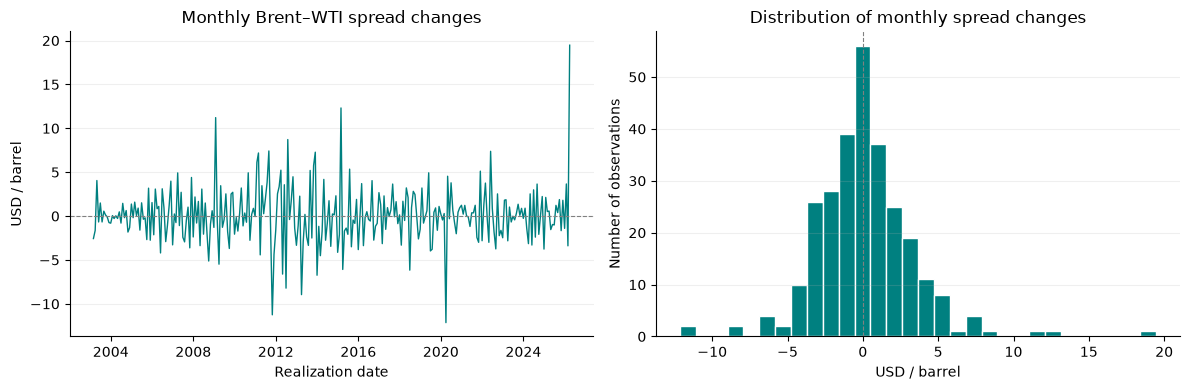

,Monthly spread change
count,278.0000
mean,0.0927
std,3.2732
min,-12.1400
25%,-1.6825
50%,-0.0400
75%,1.6625
max,19.4700
skewness,0.7716
kurtosis,8.7463


In [19]:
from scipy import stats

target = model_data["target_spread_change"]

# The target attached to decision month t is realized in month t+1
target_dates = model_data["date"] + pd.offsets.MonthEnd(1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(target_dates, target, color="teal", linewidth=1)
axes[0].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[0].set_title("Monthly Brent–WTI spread changes")
axes[0].set_xlabel("Realization date")
axes[0].set_ylabel("USD / barrel")

axes[1].hist(target, bins=30, color="teal", edgecolor="white")
axes[1].axvline(0, color="grey", linestyle="--", linewidth=0.8)
axes[1].set_title("Distribution of monthly spread changes")
axes[1].set_xlabel("USD / barrel")
axes[1].set_ylabel("Number of observations")

for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

s = target.dropna()
jb_stat, jb_pval = stats.jarque_bera(s)

stats_summary = target.describe()
stats_summary["skewness"] = s.skew()
stats_summary["kurtosis"] = s.kurtosis() + 3  
stats_summary["jarque_bera_stat"] = jb_stat
stats_summary["jarque_bera_pval"] = jb_pval

display(
    stats_summary.to_frame("Monthly spread change").style.format("{:.4f}")
)

Monthly spread changes are centred near zero, with a mean of 0.093 USD/barrel and a median of -0.040 USD/barrel. Most movements are relatively small, but the distribution contains several extreme observations, ranging from -12.14 to 19.47 USD/barrel.

The distribution strongly rejects normality (Jarque–Bera statistic = 393.40, p < 0.0001), exhibiting positive skewness (0.77) and heavy tails (kurtosis = 8.75, compared with 3.0 for a normal distribution).

These characteristics motivate reporting both RMSE, which places greater weight on large forecasting errors, and MAE, which is less sensitive to extreme observations. They also motivate examining forecasting performance across different periods.

## 5. Evaluation framework

We now define how forecasts will be generated and compared. Following the descriptive analysis, we use a zero-change forecast as a reference and assess errors using both RMSE and MAE.

The five information sets are evaluated on common dates using the same chronological forecasting procedure.

### 5.1 Development and evaluation periods

We divide the sample chronologically according to the forecast decision date:

- **Development period: before January 2017.** This period is used to examine the variables, select transformations, and specify the models.
- **Evaluation period: January 2017 onward.** This period is used to compare the historical out-of-sample forecasts of the predefined specifications.

During evaluation, models are re-estimated using only observations whose outcomes are available at each forecast date. The same evaluation dates are used across all five information sets.

Since earlier versions of the project have already examined parts of this history, this is a historical evaluation rather than a previously untouched test.

In [20]:
EVALUATION_START = pd.Timestamp("2017-01-01")
TARGET_COL = "target_spread_change"

development_data = model_data.loc[
    model_data["date"] < EVALUATION_START
].copy()

evaluation_data = model_data.loc[
    model_data["date"] >= EVALUATION_START
].copy()

sample_summary = pd.DataFrame([
    {
        "sample": name,
        "start": data["date"].min(),
        "end": data["date"].max(),
        "observations": len(data),
    }
    for name, data in [
        ("Development", development_data),
        ("Evaluation", evaluation_data),
    ]
])

display(sample_summary)

,sample,start,end,observations
0,Development,2003-01-31,2016-12-31,168
1,Evaluation,2017-01-31,2026-02-28,110



### 5.2 Rolling forecast procedure

We use a rolling training window of 120 monthly observations, corresponding to ten years.

At each month-end decision date:

1. The model is fitted on the most recent 120 observations whose next-month outcomes are already known.
2. It predicts the spread change over the following month using the predictors available at the decision date.
3. The window moves forward by one month, and the model is fitted again.

The first evaluation forecast is made at the end of January 2017 and concerns the spread change from January to February 2017. As evaluation progresses, newly observed outcomes enter subsequent training windows.

All models and information sets follow the same procedure. The ten-year window is fixed for the main experiment.


In [21]:
TRAIN_WINDOW = 120
FORECAST_HORIZON = 1
REFIT_EVERY = 1

### 5.3 Forecast evaluation metrics

The distribution of monthly spread changes contains both frequent small movements and occasional large movements. We therefore evaluate forecasts using two complementary error measures.

Our primary metric is root mean squared error:

$$
\mathrm{RMSE}
= \sqrt{\frac{1}{N}\sum_{t=1}^{N}(y_t-\hat{y}_t)^2}.
$$

RMSE gives greater weight to large errors. We also report mean absolute error to assess performance with less emphasis on extreme observations:

$$
\mathrm{MAE}
= \frac{1}{N}\sum_{t=1}^{N}|y_t-\hat{y}_t|.
$$

Both measures are expressed in US dollars per barrel.

Since monthly changes are centred near zero, we measure improvement over a zero-change forecast using:

$$
R^2_{\mathrm{zero}}
= 1-\frac{\sum_t(y_t-\hat{y}_t)^2}{\sum_t y_t^2}.
$$

A positive value indicates lower squared errors than the zero-change forecast.

We additionally report directional accuracy: the proportion of correctly predicted widening or narrowing movements. Zero forecasts are treated as neutral signals.

All specifications are compared on identical evaluation dates. The contribution of fundamentals is assessed relative to the prices-only specification using the same forecasting model.


## 6. Predictor construction

Our predictors describe two aspects of the forecasting problem: the recent behaviour of the Brent–WTI spread and changes in physical oil market conditions.

We retain a compact set of variables motivated by these economic mechanisms. The development sample is used to examine their behaviour, while their predictive contribution will be assessed through the out-of-sample comparisons.

### 6.1 Spread dynamics

We first compare the autocorrelation of the spread level and its monthly changes. This helps distinguish persistent price differences from short-term patterns in spread movements.

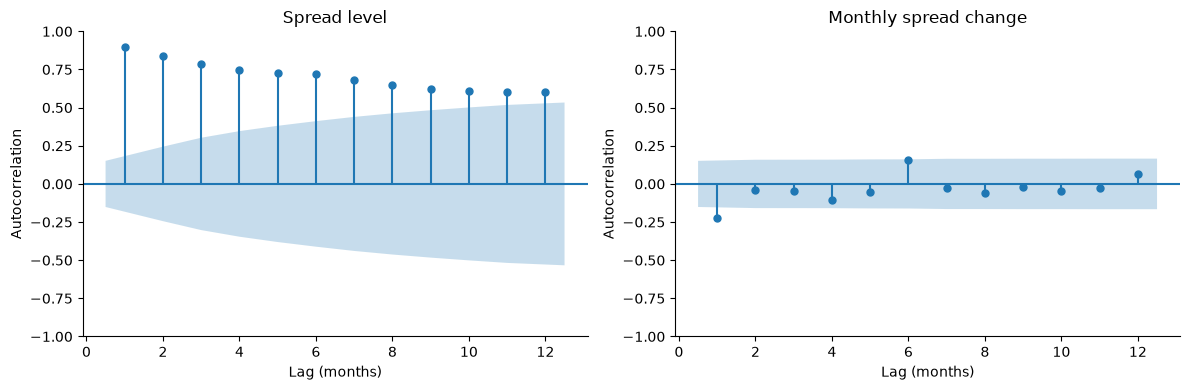

In [22]:
from statsmodels.graphics.tsaplots import plot_acf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column, title in [
    (axes[0], "spread", "Spread level"),
    (axes[1], "spread_change", "Monthly spread change"),
]:
    plot_acf(
        development_data[column].dropna(),
        lags=12,
        zero=False,
        alpha=0.05,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Lag (months)")
    ax.set_ylabel("Autocorrelation")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

The spread level exhibits strong persistence: autocorrelation is approximately 0.9 at one month and remains around 0.6 after twelve months. Relative price differences can therefore persist for extended periods.

Monthly changes show much weaker dependence. Their first-order autocorrelation is negative, approximately −0.22, suggesting some short-term reversal in the development sample. Most remaining lags lie within the plotted confidence bands.

These observations support examining the latest spread change as a predictor and including an AR(1) benchmark. They do not establish that these patterns will remain predictive out of sample.

We retain four price-based predictors:

| Predictor | Economic interpretation |
|---|---|
| Current spread | The relative price of Brent and WTI, which may contain information about subsequent adjustments |
| Latest monthly spread change | Recent movement, potentially followed by continuation or reversal |
| Six-month average spread change | The recent direction of spread movements |
| Twelve-month volatility of spread changes | The recent risk environment |

The trend and volatility variables complement the short-term movement. Their inclusion is economically motivated rather than established by the autocorrelation plots alone.

### 6.2 Fundamental transformations

The physical fundamentals describe supply, storage, trade, and refinery demand. We express inventories, production, imports, exports, and refinery intake as twelve-month percentage changes:

$$
g_t = 100\left(\frac{X_t}{X_{t-12}} - 1\right).
$$

This representation measures how market conditions have changed relative to the same month of the previous year. It also makes growth rates comparable across groups of different sizes.

The economic interpretation remains conditional on the regional oil balance:

- **Inventory growth** describes the accumulation or depletion of available crude. Accumulation in a WTI-related market could weigh on WTI relative to Brent.
- **Production growth** describes changes in domestic supply. Its price effect depends on the capacity of refining and exports to absorb additional barrels.
- **Import and export growth** describe changes in cross-border flows, which can reinforce or relieve regional imbalances.
- **Refinery-intake growth** describes changes in demand for crude from refineries.

Monthly stock changes are retained in their reported form because they already measure inventory accumulation or depletion. They complement annual inventory growth by describing more recent movements.

The same transformation rules are applied across the WTI-related, Brent-related, and pooled groups. We do not impose coefficient signs: these variables interact, and their effects may vary with market conditions.


In [23]:
def transform_jodi_fundamentals(jodi_dataset):
    """Compute annual growth rates and retain monthly stock changes."""
    data = (
        jodi_dataset.copy()
        .sort_values("date")
        .set_index("date")
        .asfreq("MS")
    )

    transformed = pd.DataFrame(index=data.index)

    for column in data.columns:
        if column.endswith("_STOCKCH"):
            transformed[column] = data[column]
        else:
            previous_year = data[column].shift(12)

            # Growth is undefined when the previous year's value is zero
            denominator = previous_year.where(previous_year.ne(0))

            transformed[f"{column}_yoy"] = (
                data[column].div(denominator).sub(1).mul(100)
            )

    return transformed.reset_index()

In [24]:
# Transform the aggregates, then apply the publication lag
jodi_transformed = transform_jodi_fundamentals(jodi_dataset)

model_data_transformed = build_model_dataset(
    monthly_prices,
    jodi_transformed,
    jodi_lag=2,
)

development_transformed = model_data_transformed.loc[
    model_data_transformed["date"] < EVALUATION_START
].copy()

evaluation_transformed = model_data_transformed.loc[
    model_data_transformed["date"] >= EVALUATION_START
].copy()

FUNDAMENTAL_FEATURES = [
    column for column in jodi_transformed.columns
    if column != "date"
]

print(f"Complete observations: {len(model_data_transformed):,}")
print(f"Development observations: {len(development_transformed):,}")
print(f"Evaluation observations: {len(evaluation_transformed):,}")
print(
    f"Period: {model_data_transformed['date'].min():%Y-%m} "
    f"to {model_data_transformed['date'].max():%Y-%m}"
)

display(development_transformed[FUNDAMENTAL_FEATURES].head())

Complete observations: 276
Development observations: 166
Evaluation observations: 110
Period: 2003-03 to 2026-02


,WTI_CLOSTLV_yoy,Brent_CLOSTLV_yoy,Pooled_CLOSTLV_yoy,WTI_STOCKCH,Brent_STOCKCH,Pooled_STOCKCH,WTI_INDPROD_yoy,Brent_INDPROD_yoy,Pooled_INDPROD_yoy,WTI_TOTIMPSB_yoy,Brent_TOTIMPSB_yoy,Pooled_TOTIMPSB_yoy,WTI_TOTEXPSB_yoy,Brent_TOTEXPSB_yoy,Pooled_TOTEXPSB_yoy,WTI_REFINOBS_yoy,Brent_REFINOBS_yoy,Pooled_REFINOBS_yoy
0,2.845440,-1.421864,1.663726,2735.82,9640.25,25821.752,1.059348,-4.697480,-4.725175,-0.587774,-1.730880,3.230011,8.169005,-1.623391,3.030238,-0.720351,-0.815823,2.229797
1,0.860288,-5.830869,0.438892,58.70,-15454.59,-11343.256,-0.950071,-1.730874,0.372656,-3.839568,-3.842788,1.958274,-1.999553,-2.040997,7.995059,0.514292,1.678140,2.825954
2,0.733005,9.565317,3.029763,6987.56,39726.08,53425.159,0.378172,5.185791,4.652752,6.004569,15.388182,6.815203,19.049964,-12.534617,6.700272,1.881490,4.198032,3.983810
3,0.967074,7.222774,2.169246,5545.11,-4511.33,-20154.000,-0.517816,-7.265682,8.901975,5.449065,3.080239,6.884801,-9.731474,-13.747513,14.527356,2.537184,6.356326,3.812799
4,0.248044,1.774380,0.844127,-2107.90,-11294.09,-16137.597,-0.998820,-8.159089,8.223071,8.679628,-1.048669,4.520053,0.111129,-3.532103,21.098104,4.544571,7.290395,3.816745


#### Complementary stationarity diagnostic

We apply the Augmented Dickey–Fuller test to the spread, its monthly changes, and the transformed fundamentals using the development sample.

The null hypothesis is that a series contains a unit root. Rejection provides evidence against this hypothesis, while failure to reject does not establish non-stationarity.

This diagnostic describes the persistence of our predictors. It is not used as an automatic selection rule for Ridge, Random Forest, or LightGBM.

In [25]:
import pandas as pd
from statsmodels.tsa.stattools import adfuller

def adf_summary(data, columns):
    """ADF tests with an intercept and AIC-based lag selection."""
    results = []

    for column in columns:
        series = data[column].dropna()

        if series.nunique() <= 1:
            raise ValueError(f"Cannot test a constant series: {column}")

        statistic, p_value, lags, nobs, *_ = adfuller(
            series,
            regression="c",
            autolag="AIC",
            result_object=False,
        )

        results.append({
            "variable": column,
            "ADF statistic": statistic,
            "p-value": p_value,
            "lags": lags,
            "observations": nobs,
            "reject unit root (5%)": p_value < 0.05,
        })

    return pd.DataFrame(results).set_index("variable")

In [26]:
adf_results = adf_summary(
    development_transformed,
    ["spread", "spread_change"] + FUNDAMENTAL_FEATURES,
)

display(adf_results.round(4))

,ADF statistic,p-value,lags,observations,reject unit root (5%)
variable,,,,,
spread,-2.4467,0.1290,1,164,False
spread_change,-8.0302,0.0000,4,161,True
WTI_CLOSTLV_yoy,-2.2095,0.2028,14,151,False
Brent_CLOSTLV_yoy,-3.0266,0.0325,13,152,True
Pooled_CLOSTLV_yoy,-2.7512,0.0656,14,151,False
WTI_STOCKCH,-2.3257,0.1638,12,153,False
Brent_STOCKCH,-10.1888,0.0000,3,162,True
Pooled_STOCKCH,-3.2400,0.0178,14,151,True
WTI_INDPROD_yoy,-1.5356,0.5158,12,153,False


The ADF diagnostic complements our economic motivation for transforming fundamentals. Physical quantities may exhibit persistent trends, whereas annual growth rates describe changes in regional supply, storage, trade, and refining conditions.

The results remain mixed: several transformed series do not reject the unit-root hypothesis. We therefore do not claim that annual growth rates guarantee stationarity. We retain them for their economic interpretation and apply the same rules across geographical groups.

Monthly stock changes remain in their reported form because they already measure inventory accumulation or depletion. The usefulness of these predictors will ultimately be assessed through out-of-sample forecasting.

### 6.3 Final predictor sets

We combine the four price-based predictors with the transformed fundamentals to construct the five information sets introduced in Section 3.

| Specification | Economic question | Number of predictors |
|---|---|---:|
| Prices only | How much can past spread dynamics predict? | 4 |
| Prices + WTI fundamentals | Do North American conditions provide additional information? | 10 |
| Prices + Brent fundamentals | Do European conditions provide additional information? | 10 |
| Prices + both regional blocks | Does distinguishing the two regional balances help? | 16 |
| Prices + pooled fundamentals | Are broader conditions sufficient without separating regions? | 10 |

The regional and pooled specifications are estimated separately. Pooled aggregates are not added alongside their regional components.

All five specifications use the same monthly sample and evaluation dates. Differences in forecast performance can therefore be compared without changes in sample composition.

In [27]:
WTI_FEATURES = [
    col for col in FUNDAMENTAL_FEATURES
    if col.startswith("WTI_")
]

BRENT_FEATURES = [
    col for col in FUNDAMENTAL_FEATURES
    if col.startswith("Brent_")
]

POOLED_FEATURES = [
    col for col in FUNDAMENTAL_FEATURES
    if col.startswith("Pooled_")
]

FEATURE_SETS = {
    "prices_only": PRICE_FEATURES.copy(),
    "prices_wti": PRICE_FEATURES + WTI_FEATURES,
    "prices_brent": PRICE_FEATURES + BRENT_FEATURES,
    "prices_both_regions": PRICE_FEATURES + WTI_FEATURES + BRENT_FEATURES,
    "prices_pooled": PRICE_FEATURES + POOLED_FEATURES,
}

model_sample = (
    model_data_transformed
    .sort_values("date")
    .reset_index(drop=True)
)

display(pd.DataFrame([
    {
        "specification": name,
        "predictors": len(columns),
    }
    for name, columns in FEATURE_SETS.items()
]))

,specification,predictors
0,prices_only,4
1,prices_wti,10
2,prices_brent,10
3,prices_both_regions,16
4,prices_pooled,10


## 7. Forecasting results

We now generate monthly forecasts using the rolling procedure defined in Section 5. We first establish simple benchmarks, then compare Ridge, Random Forest, and LightGBM across the five information sets.

### 7.1 Statistical benchmarks

We consider three reference forecasts:

- **Zero change:** the spread remains unchanged over the following month.
- **Historical mean:** the forecast equals the average spread change observed in the training window.
- **AR(1):** the forecast depends linearly on the latest observed monthly spread change:

$$
\widehat{\Delta S}_{t+1}
= \hat{\alpha}_t + \hat{\beta}_t \Delta S_t.
$$

The AR(1) benchmark captures a simple continuation or reversal mechanism, motivated by the negative first-order autocorrelation observed in the development sample.

The historical mean and AR(1) are re-estimated each month using the previous 120 observations. The benchmarks use no fundamental information and are calculated once for the common evaluation sample.


In [28]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
import numpy as np

def rolling_benchmarks(
    data,
    evaluation_start,
    train_window=120,
    target_col="target_spread_change",
):
    """Generate one-month-ahead benchmark forecasts."""
    df = data.sort_values("date").reset_index(drop=True).copy()
    evaluation_start = pd.Timestamp(evaluation_start)

    forecasts = []

    for i in df.index[df["date"] >= evaluation_start]:
        if i < train_window:
            raise ValueError(
                f"Insufficient training history at {df.loc[i, 'date']}."
            )

        # The preceding row's target is known at the current decision date
        train = df.iloc[i - train_window:i]
        current = df.iloc[[i]]

        ar1 = LinearRegression()
        ar1.fit(
            train[["spread_change"]],
            train[target_col],
        )

        predictions = {
            "zero_change": 0.0,
            "historical_mean": train[target_col].mean(),
            "ar1": ar1.predict(current[["spread_change"]])[0],
        }

        for name, prediction in predictions.items():
            forecasts.append({
                "date": current["date"].iloc[0],
                "model": name,
                "y_true": current[target_col].iloc[0],
                "y_pred": float(prediction),
            })

    return pd.DataFrame(forecasts)


In [29]:
benchmark_predictions = rolling_benchmarks(
    data=model_sample,
    evaluation_start=EVALUATION_START,
    train_window=TRAIN_WINDOW,
    target_col=TARGET_COL,
)

print(
    "Monthly forecasts per benchmark:",
    benchmark_predictions["date"].nunique(),
)

display(
    benchmark_predictions.pivot(
        index="date",
        columns="model",
        values="y_pred",
    ).head()
)

Monthly forecasts per benchmark: 110


model,ar1,historical_mean,zero_change
date,,,
2017-01-31,-0.226441,0.034583,0.0
2017-02-28,0.676519,0.014583,0.0
2017-03-31,-0.485815,-0.007250,0.0
2017-04-30,0.305713,-0.010833,0.0
2017-05-31,-0.228965,-0.025417,0.0


### 7.2 Ridge, Random Forest and LightGBM

We compare three complementary forecasting models:

- **Ridge regression** captures linear relationships while shrinking coefficients to limit estimation variance. Predictors are standardized within each training window.
- **LightGBM** captures nonlinear relationships using shallow boosted trees. Its complexity is restricted given the small monthly sample.
- **Random Forest** averages randomized regression trees to capture nonlinear relationships. Tree depth and minimum leaf size are restricted to control complexity in the small monthly sample.

Ridge's penalty is selected from a predefined grid using chronological validation within each training window. Scaling is fitted separately within each validation fold. LightGBM and Random Forest use fixed parameters.

All three models are re-estimated monthly over the same 120-month windows and evaluated across the five information sets.

In [30]:
def get_ml_models():
    """Define the two forecasting models and their fixed settings."""
    ridge = GridSearchCV(
        estimator=make_pipeline(
            StandardScaler(),
            Ridge(),
        ),
        param_grid={"ridge__alpha": [10, 100, 1000]},
        cv=TimeSeriesSplit(n_splits=3, test_size=12),
        scoring="neg_mean_squared_error",
        refit=True,
        n_jobs=1,
        error_score="raise",
    )

    lightgbm = LGBMRegressor(
        n_estimators=60,
        learning_rate=0.05,
        max_depth=2,
        num_leaves=4,
        min_child_samples=15,
        random_state=42,
        n_jobs=1,
        verbosity=-1,
    )

    return {
    "ridge": ridge,
    "lightgbm": lightgbm,
    "random_forest": RandomForestRegressor(
        n_estimators=80,
        max_depth=3,
        min_samples_leaf=8,
        max_features="sqrt",
        random_state=42,
        n_jobs=1,
    ),
}


def rolling_ml_forecasts(
    data,
    feature_sets,
    evaluation_start,
    train_window=120,
    target_col="target_spread_change",
    return_diagnostics=False,
):
    """Generate rolling forecasts and optionally retain model diagnostics."""
    df = data.sort_values("date").reset_index(drop=True).copy()
    evaluation_start = pd.Timestamp(evaluation_start)
    evaluation_indices = df.index[df["date"] >= evaluation_start]

    if len(evaluation_indices) == 0:
        raise ValueError("No observations in the evaluation period.")

    if evaluation_indices[0] < train_window:
        raise ValueError("Insufficient history for the first forecast.")

    models = get_ml_models()
    forecasts = []
    diagnostics = []

    for feature_set, columns in feature_sets.items():
        for model_name, estimator in models.items():
            print(f"Running {model_name} | {feature_set}")

            for i in evaluation_indices:
                train = df.iloc[i - train_window:i]
                current = df.iloc[[i]]
                date = current["date"].iloc[0]

                fitted = clone(estimator)
                fitted.fit(train[columns], train[target_col])

                prediction = fitted.predict(current[columns])[0]

                forecasts.append({
                    "date": date,
                    "feature_set": feature_set,
                    "model": model_name,
                    "y_true": current[target_col].iloc[0],
                    "y_pred": float(prediction),
                    "ridge_alpha": (
                        fitted.best_params_["ridge__alpha"]
                        if model_name == "ridge"
                        else float("nan")
                    ),
                })

                # Interpret the economically motivated two-region specification
                if (
                    return_diagnostics
                    and feature_set == "prices_both_regions"
                    and model_name in ("ridge", "lightgbm")
                ):
                    if model_name == "ridge":
                        values = (
                            fitted.best_estimator_
                            .named_steps["ridge"]
                            .coef_
                        )
                    else:
                        values = fitted.booster_.feature_importance(
                            importance_type="gain"
                        ).astype(float)

                        # Express gain as a percentage within each fitted model
                        if values.sum() > 0:
                            values = 100 * values / values.sum()

                    diagnostics.extend([
                        {
                            "date": date,
                            "feature_set": feature_set,
                            "model": model_name,
                            "feature": feature,
                            "value": float(value),
                        }
                        for feature, value in zip(columns, values)
                    ])

    predictions = pd.DataFrame(forecasts)

    if return_diagnostics:
        return predictions, pd.DataFrame(diagnostics)

    return predictions


In [31]:
ml_predictions, model_diagnostics = rolling_ml_forecasts(
    data=model_sample,
    feature_sets=FEATURE_SETS,
    evaluation_start=EVALUATION_START,
    train_window=TRAIN_WINDOW,
    target_col=TARGET_COL,
    return_diagnostics=True,
)

Running ridge | prices_only
Running lightgbm | prices_only
Running random_forest | prices_only
Running ridge | prices_wti
Running lightgbm | prices_wti
Running random_forest | prices_wti
Running ridge | prices_brent
Running lightgbm | prices_brent
Running random_forest | prices_brent
Running ridge | prices_both_regions
Running lightgbm | prices_both_regions
Running random_forest | prices_both_regions
Running ridge | prices_pooled
Running lightgbm | prices_pooled
Running random_forest | prices_pooled


### 7.3 Comparison of the five information sets

We compare all forecasts on identical evaluation dates using RMSE, MAE,
the benchmark-relative R², correlation, and directional accuracy.

Directional accuracy is calculated for non-zero forecasts. Signal
coverage reports the proportion of forecasts giving a directional
signal; the zero-change benchmark therefore has no directional accuracy.

We first compare all configurations, then measure the contribution of
fundamentals relative to the prices-only specification within each model.

In [32]:
def forecast_metrics(predictions):
    """Evaluate forecasts against their observed outcomes."""
    y_true = predictions["y_true"].to_numpy(dtype=float)
    y_pred = predictions["y_pred"].to_numpy(dtype=float)
    errors = y_true - y_pred

    zero_loss = np.sum(y_true ** 2)
    active = y_pred != 0

    correlation = (
        np.corrcoef(y_true, y_pred)[0, 1]
        if np.std(y_true) > 0 and np.std(y_pred) > 0
        else np.nan
    )

    return {
        "n_forecasts": len(predictions),
        "rmse": np.sqrt(np.mean(errors ** 2)),
        "mae": np.mean(np.abs(errors)),
        "r2_zero": (
            1 - np.sum(errors ** 2) / zero_loss
            if zero_loss > 0 else np.nan
        ),
        "correlation": correlation,
        "directional_accuracy": (
            np.mean(np.sign(y_true[active]) == np.sign(y_pred[active]))
            if active.any() else np.nan
        ),
        "signal_coverage": active.mean(),
    }

def evaluate_forecasts(predictions):
    """Compare configurations using identical dates and outcomes."""
    keys = ["model", "feature_set", "date"]

    if predictions.duplicated(keys).any():
        raise ValueError("Duplicate forecasts within a configuration.")

    if predictions[["y_true", "y_pred"]].isna().any().any():
        raise ValueError("Missing forecasts or observed outcomes.")

    if predictions.groupby("date")["y_true"].nunique().gt(1).any():
        raise ValueError("Observed outcomes differ across configurations.")

    reference_dates = set(predictions["date"])
    results = []

    for (model, feature_set), group in predictions.groupby(
        ["model", "feature_set"]
    ):
        if set(group["date"]) != reference_dates:
            raise ValueError(
                f"Evaluation dates differ: {model}, {feature_set}"
            )

        results.append({
            "model": model,
            "feature_set": feature_set,
            **forecast_metrics(group),
        })

    return pd.DataFrame(results).sort_values("rmse").reset_index(drop=True)

In [33]:
all_predictions = pd.concat(
    [
        benchmark_predictions.assign(feature_set="benchmark"),
        ml_predictions,
    ],
    ignore_index=True,
)

comparison_results = evaluate_forecasts(all_predictions)

display(
    comparison_results.style.format({
        "rmse": "{:.3f}",
        "mae": "{:.3f}",
        "r2_zero": "{:.3f}",
        "correlation": "{:.3f}",
        "directional_accuracy": "{:.1%}",
        "signal_coverage": "{:.1%}",
    }, na_rep="—")
)

,model,feature_set,n_forecasts,rmse,mae,r2_zero,correlation,directional_accuracy,signal_coverage
0,ridge,prices_only,110,2.945,1.768,0.121,0.370,70.9%,100.0%
1,random_forest,prices_only,110,2.948,1.776,0.119,0.349,65.5%,100.0%
2,ar1,benchmark,110,2.968,1.889,0.107,0.371,60.0%,100.0%
3,random_forest,prices_pooled,110,2.986,1.850,0.096,0.328,65.5%,100.0%
4,lightgbm,prices_only,110,2.996,1.790,0.091,0.296,66.4%,100.0%
5,ridge,prices_brent,110,3.000,1.874,0.088,0.291,68.2%,100.0%
6,random_forest,prices_wti,110,3.014,1.875,0.079,0.282,60.9%,100.0%
7,random_forest,prices_brent,110,3.020,1.885,0.076,0.277,67.3%,100.0%
8,ridge,prices_pooled,110,3.021,1.878,0.075,0.282,65.5%,100.0%
9,random_forest,prices_both_regions,110,3.027,1.920,0.072,0.283,63.6%,100.0%


In [34]:
directional_results = comparison_results.sort_values(
    "directional_accuracy",
    ascending=False,
    na_position="last",
)

display(
    directional_results[
        [
            "model",
            "feature_set",
            "directional_accuracy",
            "signal_coverage",
            "rmse",
            "mae",
        ]
    ].style.format({
        "directional_accuracy": "{:.1%}",
        "signal_coverage": "{:.1%}",
        "rmse": "{:.3f}",
        "mae": "{:.3f}",
    }, na_rep="—")
)

,model,feature_set,directional_accuracy,signal_coverage,rmse,mae
0,ridge,prices_only,70.9%,100.0%,2.945,1.768
5,ridge,prices_brent,68.2%,100.0%,3.000,1.874
7,random_forest,prices_brent,67.3%,100.0%,3.020,1.885
11,lightgbm,prices_brent,67.3%,100.0%,3.049,1.876
4,lightgbm,prices_only,66.4%,100.0%,2.996,1.790
10,ridge,prices_both_regions,65.5%,100.0%,3.045,1.907
1,random_forest,prices_only,65.5%,100.0%,2.948,1.776
8,ridge,prices_pooled,65.5%,100.0%,3.021,1.878
3,random_forest,prices_pooled,65.5%,100.0%,2.986,1.850
9,random_forest,prices_both_regions,63.6%,100.0%,3.027,1.920


Our first question is whether past spread dynamics contain useful forecasting information. The AR(1) benchmark improves on the zero-change forecast, reducing RMSE from 3.141 to 2.968 USD/barrel. This is consistent with the short-term dependence identified in Section 6.

Using the four price predictors, Ridge achieves an RMSE of 2.945 USD/barrel, an MAE of 1.768, and a directional accuracy of 70.9%. Random Forest produces a similar RMSE of 2.948, while LightGBM reaches 2.996. The compact price-based information set therefore provides a strong reference before introducing fundamentals.

Unlike in the previous data vintage, none of the fundamental-augmented specifications improves upon the corresponding prices-only model in RMSE. This suggests that the additional physical variables do not provide a consistent point-forecasting advantage in the current evaluation sample.

In [35]:
prices_reference = (
    comparison_results.loc[
        comparison_results["feature_set"].eq("prices_only"),
        ["model", "rmse", "mae"],
    ]
    .rename(columns={
        "rmse": "prices_rmse",
        "mae": "prices_mae",
    })
)

fundamental_comparison = (
    comparison_results.loc[
        ~comparison_results["feature_set"].isin(
            ["benchmark", "prices_only"]
        )
    ]
    .merge(prices_reference, on="model", validate="many_to_one")
)

fundamental_comparison["rmse_improvement_pct"] = 100 * (
    1 - fundamental_comparison["rmse"]
    / fundamental_comparison["prices_rmse"]
)

fundamental_comparison["mae_improvement_pct"] = 100 * (
    1 - fundamental_comparison["mae"]
    / fundamental_comparison["prices_mae"]
)

display(
    fundamental_comparison[
        [
            "model",
            "feature_set",
            "rmse",
            "mae",
            "rmse_improvement_pct",
            "mae_improvement_pct",
        ]
    ]
    .sort_values(["model", "rmse"])
    .style.format({
        "rmse": "{:.3f}",
        "mae": "{:.3f}",
        "rmse_improvement_pct": "{:+.2f}",
        "mae_improvement_pct": "{:+.2f}",
    })
)

,model,feature_set,rmse,mae,rmse_improvement_pct,mae_improvement_pct
7,lightgbm,prices_brent,3.049,1.876,-1.77,-4.82
9,lightgbm,prices_both_regions,3.089,1.987,-3.14,-10.98
10,lightgbm,prices_pooled,3.091,1.959,-3.18,-9.43
11,lightgbm,prices_wti,3.094,1.999,-3.29,-11.66
0,random_forest,prices_pooled,2.986,1.850,-1.30,-4.17
2,random_forest,prices_wti,3.014,1.875,-2.23,-5.59
3,random_forest,prices_brent,3.020,1.885,-2.43,-6.16
5,random_forest,prices_both_regions,3.027,1.920,-2.67,-8.14
1,ridge,prices_brent,3.000,1.874,-1.85,-5.97
4,ridge,prices_pooled,3.021,1.878,-2.56,-6.18


The within-model comparisons provide no evidence of incremental point-forecasting gains from the JODI fundamentals in the current sample. Every fundamental-augmented specification increases both RMSE and MAE relative to its corresponding prices-only model.

For Ridge, adding both regional blocks increases RMSE by 3.39% and MAE by 7.87%. Brent-related fundamentals produce the smallest deterioration for LightGBM, with RMSE increasing by 1.77% and MAE by 4.82%. For Random Forest, pooled fundamentals produce the smallest RMSE deterioration, at 1.30%.

The geographical distinction nevertheless matters for directional predictions. Brent-related fundamentals increase Random Forest's directional accuracy from 65.5% to 67.3%, despite worsening its magnitude-based forecast errors. Pooled fundamentals also increase RMSE across all three models.

Thus, economically plausible physical mechanisms do not translate into improved point forecasts in this evaluation. We next examine whether the additional variables alter forecasting performance across different periods.

### 7.4 Stability and interpretation of results

Aggregate metrics can conceal differences across time. We therefore
examine annual forecast errors and the cumulative contribution of
fundamentals relative to prices alone.

An upward movement in cumulative error reduction indicates that the
fundamental specification incurred smaller squared errors than its
prices-only counterpart. A downward movement indicates the opposite.

These comparisons describe the timing of forecasting gains and losses;
they do not establish statistical significance.

In [36]:
annual_errors = all_predictions.assign(
    year=all_predictions["date"].dt.year,
    squared_error=(
        all_predictions["y_true"] - all_predictions["y_pred"]
    ) ** 2,
)

annual_rmse = (
    annual_errors
    .groupby(["model", "feature_set", "year"])["squared_error"]
    .mean()
    .pow(0.5)
    .unstack("year")
)

display(annual_rmse.round(2))

year                                 2017  2018  2019  2020  2021  2022  2023  \
model           feature_set                                                     
ar1             benchmark            1.87  2.73  2.26  3.86  1.89  3.16  1.14   
historical_mean benchmark            1.98  2.74  2.27  4.00  2.14  3.15  1.18   
lightgbm        prices_both_regions  2.13  2.78  2.64  3.88  1.97  3.11  1.20   
                prices_brent         1.73  2.57  2.86  3.75  1.98  3.19  1.14   
                prices_only          1.87  2.71  2.19  3.84  1.97  3.23  1.20   
                prices_pooled        1.98  3.07  2.48  3.89  2.00  3.47  1.22   
                prices_wti           2.26  3.18  2.18  3.75  2.06  3.14  1.20   
random_forest   prices_both_regions  1.86  2.78  2.21  3.94  1.96  3.04  1.14   
                prices_brent         1.78  2.65  2.23  3.94  1.99  3.13  1.06   
                prices_only          1.83  2.74  2.08  3.87  1.83  3.12  1.19   
                prices_pooled        1.99  2.73  2.17  3.86  1.93  3.12  1.00   
                prices_wti           1.99  2.78  2.06  3.98  2.02  3.04  1.10   
ridge           prices_both_regions  2.15  2.70  2.25  3.87  2.06  3.01  1.10   
                prices_brent         1.90  2.69  2.33  3.57  2.16  2.99  1.13   
                prices_only          1.83  2.62  2.14  3.81  1.77  3.02  1.01   
                prices_pooled        2.15  2.68  2.23  3.88  2.16  2.97  1.03   
                prices_wti           2.09  2.73  2.23  4.00  2.04  3.02  1.05   
zero_change     benchmark            1.97  2.74  2.25  3.98  2.15  3.15  1.18   

year                                 2024  2025   2026  
model           feature_set                             
ar1             benchmark            2.09  1.50  13.05  
historical_mean benchmark            2.67  1.61  13.98  
lightgbm        prices_both_regions  2.09  1.48  13.76  
                prices_brent         2.02  1.49  13.79  
                prices_only          1.85  1.33  13.61  
                prices_pooled        1.91  1.35  13.40  
                prices_wti           2.12  1.49  13.74  
random_forest   prices_both_regions  2.19  1.58  13.57  
                prices_brent         2.16  1.55  13.63  
                prices_only          1.88  1.40  13.31  
                prices_pooled        2.07  1.43  13.41  
                prices_wti           2.06  1.45  13.55  
ridge           prices_both_regions  2.12  1.73  13.66  
                prices_brent         2.13  1.73  13.64  
                prices_only          2.10  1.51  13.46  
                prices_pooled        2.07  1.55  13.55  
                prices_wti           2.06  1.59  13.72  
zero_change     benchmark            2.66  1.62  13.97

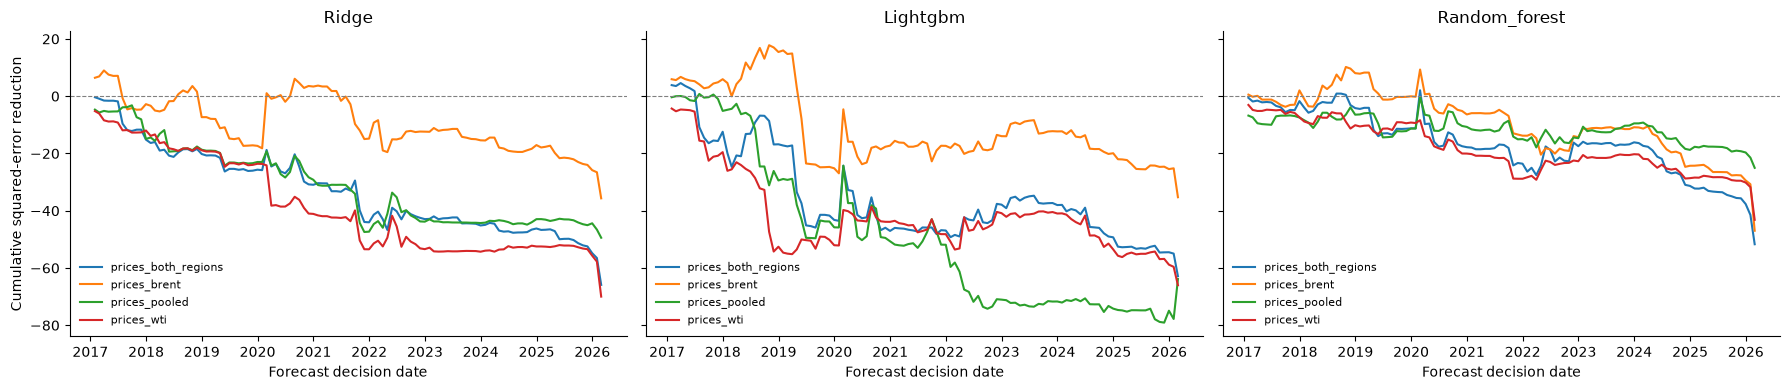

In [37]:
ml_errors = ml_predictions.assign(
    squared_error=(
        ml_predictions["y_true"] - ml_predictions["y_pred"]
    ) ** 2,
)

price_errors = (
    ml_errors.loc[
        ml_errors["feature_set"].eq("prices_only"),
        ["date", "model", "squared_error"],
    ]
    .rename(columns={"squared_error": "prices_squared_error"})
)

error_differences = (
    ml_errors.loc[~ml_errors["feature_set"].eq("prices_only")]
    .merge(
        price_errors,
        on=["date", "model"],
        validate="many_to_one",
    )
    .sort_values(["model", "feature_set", "date"])
)

error_differences["error_reduction"] = (
    error_differences["prices_squared_error"]
    - error_differences["squared_error"]
)

error_differences["cumulative_reduction"] = (
    error_differences
    .groupby(["model", "feature_set"])["error_reduction"]
    .cumsum()
)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)

for ax, model in zip(axes, ["ridge", "lightgbm", "random_forest"]):
    subset = error_differences.loc[
        error_differences["model"].eq(model)
    ]

    for feature_set, group in subset.groupby("feature_set"):
        ax.plot(
            group["date"],
            group["cumulative_reduction"],
            label=feature_set,
        )

    ax.axhline(0, color="grey", linestyle="--", linewidth=0.8)
    ax.set_title(model.capitalize())
    ax.set_xlabel("Forecast decision date")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel("Cumulative squared-error reduction")
plt.tight_layout()
plt.show()

The time profiles highlight the instability of forecasting performance across the evaluation period. Forecast errors vary substantially across years, with relatively moderate errors in several periods and pronounced increases during episodes of large spread movements.

The partial 2026 period is particularly influential, with annual RMSE exceeding 13 USD/barrel across the main specifications. These observations can have a disproportionate effect on full-sample RMSE because squared errors assign greater weight to large forecast misses.

Although some fundamental specifications perform relatively well during individual periods, none achieves a lower full-sample RMSE than its corresponding prices-only reference. The evidence therefore does not establish a persistent forecasting advantage from incorporating delayed oil fundamentals.

In [38]:
def plot_ridge_penalties(predictions):

    """Display each specification separately on a common log scale."""
    alphas = (
        predictions.loc[predictions["model"].eq("ridge")]
        .pivot(
            index="date",
            columns="feature_set",
            values="ridge_alpha",
        )
        .sort_index()
    )

    labels = {
        "prices_only": "Prices only",
        "prices_wti": "Prices + WTI fundamentals",
        "prices_brent": "Prices + Brent fundamentals",
        "prices_both_regions": "Prices + both regional blocks",
        "prices_pooled": "Prices + pooled fundamentals",
    }

    fig, axes = plt.subplots(
        len(labels),
        1,
        figsize=(11, 10),
        sharex=True,
        sharey=True,
        squeeze=False,
        constrained_layout=True,
    )

    for ax, (column, label) in zip(axes[:, 0], labels.items()):
        ax.step(
            alphas.index,
            alphas[column],
            where="post",
            color="teal",
            linewidth=1.3,
        )
        ax.set_yscale("log")
        ax.set_title(label, loc="left", fontsize=10)
        ax.set_ylabel("Alpha")
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    axes[-1, 0].set_xlabel("Forecast decision date")
    fig.suptitle("Ridge penalty selected within each training window")

    plt.show()


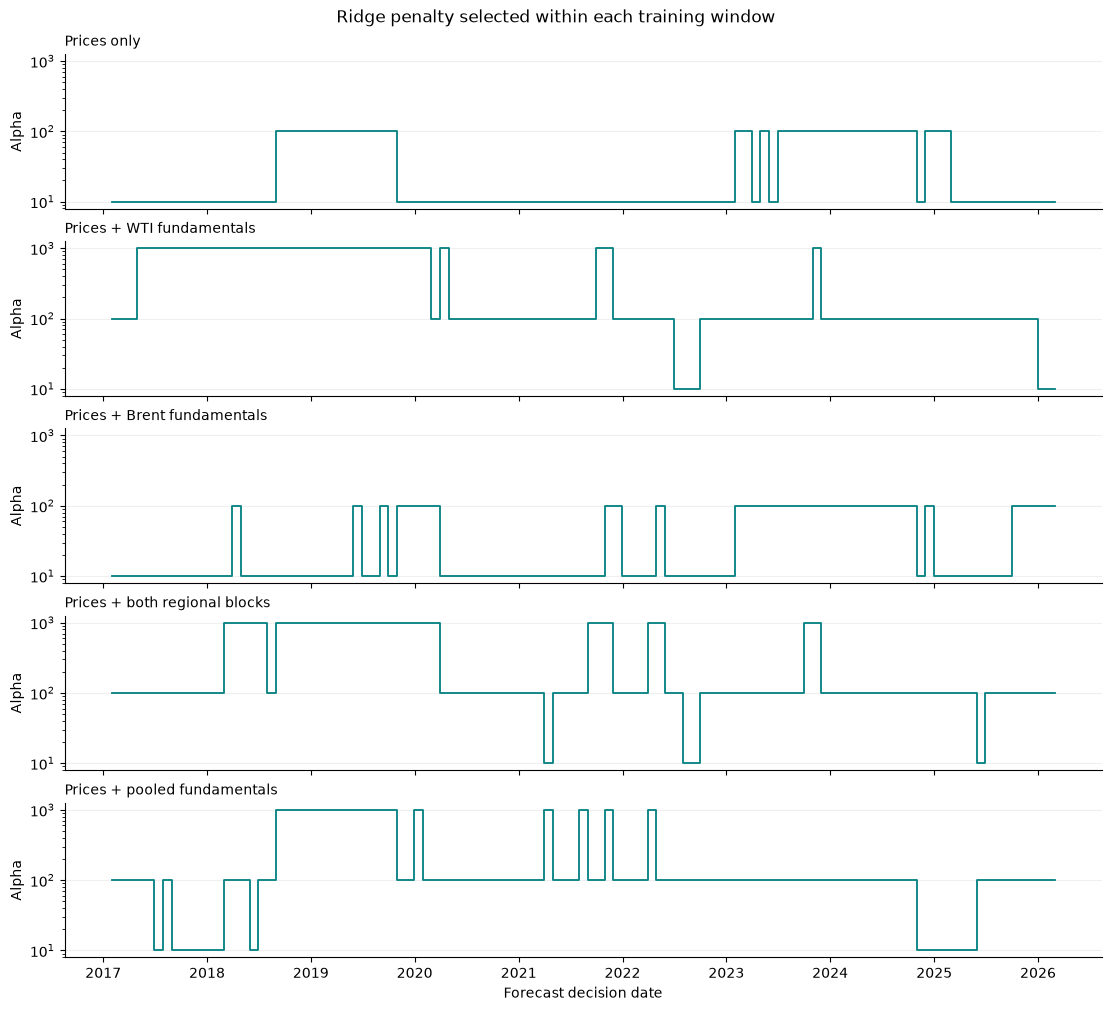

In [39]:
plot_ridge_penalties(ml_predictions)

The penalty paths help describe how Ridge fits the different information sets. Some fundamental specifications select stronger shrinkage early in the evaluation period, while a penalty of 100 becomes common across specifications later on.

The number of predictors is fixed within each specification, so changes over time reflect the validation results of successive training windows. They cannot be attributed to an increasing number of variables. Standardization also prevents the original physical units from mechanically determining the penalty.

These paths describe regularization, but do not identify which economic variables drive the forecasts. We examine the fitted coefficients and feature importance next.

### 7.5 What drives the forecasts?

The preceding comparisons show that adding fundamentals rarely improves
forecast errors consistently. We now examine how the fitted models use
these variables and relate their predictions to our initial economic
intuition.

We focus on the specification containing both regional blocks. This
preserves the distinction between WTI-related and Brent-related
conditions and allows us to examine inventories, supply, trade, and
refinery activity alongside the price predictors.

For Ridge, a positive coefficient associates a higher predictor value
with an expected widening of the spread, conditional on the other
variables. A negative coefficient indicates an expected narrowing.
Coefficients are averaged across rolling fits and refer to predictors
standardized within each training window.

For LightGBM, we report each variable's share of the training-loss
reduction, normalized within each fitted model and then averaged over
time. This measures how the trees use a variable, without giving the
direction of its effect.

These measures describe the fitted models. A variable can receive
substantial weight or importance without improving out-of-sample forecasts.

In [40]:
def plot_forecast_drivers(diagnostics):
    """Compare mean standardized Ridge coefficients and LightGBM gains."""
    summary = (
        diagnostics
        .groupby(["feature", "model"])["value"]
        .mean()
        .unstack("model")
    )

    # Use the same feature order in both panels
    summary = summary.sort_values("lightgbm")

    price_labels = {
        "spread": "Current spread",
        "spread_change": "Latest spread change",
        "spread_change_mean_6": "Six-month trend",
        "spread_change_vol_12": "Twelve-month volatility",
    }

    flow_labels = {
        "CLOSTLV": "inventory growth",
        "STOCKCH": "stock change",
        "INDPROD": "production growth",
        "TOTIMPSB": "import growth",
        "TOTEXPSB": "export growth",
        "REFINOBS": "refinery-intake growth",
    }

    def feature_label(feature):
        if feature in price_labels:
            return price_labels[feature]

        region, flow = feature.removesuffix("_yoy").split("_", 1)
        return f"{region}: {flow_labels.get(flow, flow)}"

    labels = [feature_label(feature) for feature in summary.index]

    fig, axes = plt.subplots(
        1, 2, figsize=(14, 8), sharey=True,
        constrained_layout=True,
    )

    colors = [
        "teal" if value >= 0 else "indianred"
        for value in summary["ridge"]
    ]

    axes[0].barh(labels, summary["ridge"], color=colors)
    axes[0].axvline(0, color="grey", linewidth=0.8)
    axes[0].set_title("Ridge — average standardized coefficients")
    axes[0].set_xlabel("USD / barrel per training-sample standard deviation")

    axes[1].barh(labels, summary["lightgbm"], color="steelblue")
    axes[1].set_title("LightGBM — average share of training gain")
    axes[1].set_xlabel("Gain share (%)")

    for ax in axes:
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    plt.show()   

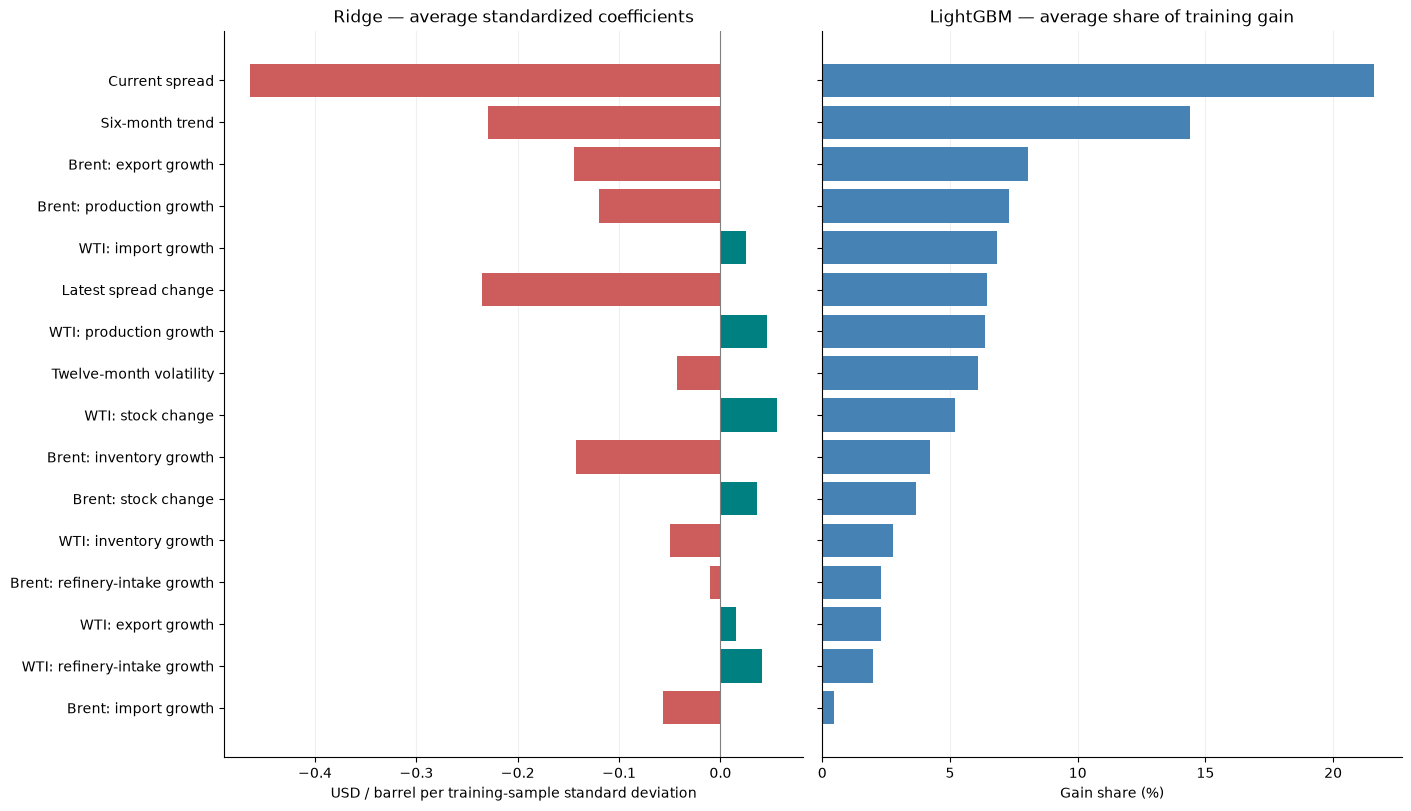

In [41]:
plot_forecast_drivers(model_diagnostics)

Both models assign a prominent role to past spread dynamics. The current spread and six-month trend are the two largest sources of LightGBM training gain. In Ridge, their average coefficients are negative, as is the coefficient of the latest monthly change. Conditional on the other predictors, wider spreads and recent widening are therefore associated with subsequent narrowing. This is consistent with the short-term reversal observed in our autocorrelation analysis.

Some fundamental relationships also match our regional intuition. WTI-related production growth has a positive average Ridge coefficient: additional regional supply is associated with an expected widening of the spread. Brent-related production and inventory growth have negative coefficients, consistent with greater availability in that region weighing on Brent relative to WTI. Brent-related export and production growth also rank among LightGBM's more important predictors.

However, the inventory results are not uniform. WTI monthly stock accumulation has a positive average coefficient, consistent with our initial hypothesis, while annual inventory growth has a negative coefficient. The two measures capture different horizons, and their conditional relationships do not support a single inventory mechanism across all specifications. These averages may also conceal changes in coefficient signs over time.

The models therefore use economically interpretable fundamental information, but this does not translate into a consistent reduction in forecast errors, as shown in Sections 7.3 and 7.4. This distinction leads to our final question: can the forecasts nevertheless improve a trading strategy once position sizing and transaction costs are considered?

## 8. Trading strategy

We translate the out-of-sample forecasts into a monthly long–short strategy. The same trading rule is applied to all forecasting configurations, allowing us to compare the economic contribution of their information sets.

### 8.1 From forecasts to positions

At each decision date, the forecast determines the direction of an equal-barrel position:

- A positive forecast leads to buying Brent and selling WTI.
- A negative forecast leads to selling Brent and buying WTI.
- A zero forecast leads to no position.

For the initial strategy, we trade one barrel on each leg. The signed position is:

$$
q_t = \operatorname{sign}(\widehat{\Delta S}_{t+1}).
$$

The position is held until the next monthly observation. Its gross profit or loss is:

$$
\mathrm{PnL}^{gross}_{t+1}
= q_t \left[
(P^{Brent}_{t+1}-P^{Brent}_t)
-
(P^{WTI}_{t+1}-P^{WTI}_t)
\right]
= q_t\Delta S_{t+1}.
$$

Forecasts are already aligned with the following month's outcome, so no additional signal shift is applied.

This initial comparison uses fixed quantities and reports dollar P&L. Transaction costs and position sizing are introduced in the next subsection. Using spot prices makes this a stylized spread-trading simulation.


In [42]:
import numpy as np
import pandas as pd

def build_spread_positions(predictions, monthly_prices):
    """Convert forecasts into equal-barrel positions and gross P&L."""
    market = (
        monthly_prices[["date", "price_date", "Brent", "WTI"]]
        .sort_values("date")
        .copy()
    )

    # Identify the next monthly observation before joining forecasts
    market["realization_date"] = market["date"].shift(-1)
    market["exit_price_date"] = market["price_date"].shift(-1)
    market["next_Brent"] = market["Brent"].shift(-1)
    market["next_WTI"] = market["WTI"].shift(-1)

    trades = predictions.merge(
        market,
        on="date",
        how="left",
        validate="many_to_one",
    )

    required = [
        "y_pred", "y_true", "Brent", "WTI",
        "next_Brent", "next_WTI",
        "price_date", "exit_price_date", "realization_date",
    ]

    if trades[required].isna().any().any():
        raise ValueError("Missing forecasts, outcomes or trading prices.")

    trades["realized_spread_change"] = (
        trades["next_Brent"] - trades["Brent"]
        - trades["next_WTI"] + trades["WTI"]
    )

    if not np.allclose(
        trades["realized_spread_change"],
        trades["y_true"],
    ):
        raise ValueError("Forecast outcomes and trading dates do not match.")

    trades["position"] = np.sign(trades["y_pred"]).astype(int)
    trades["brent_quantity"] = trades["position"]
    trades["wti_quantity"] = -trades["position"]

    trades["pnl_gross"] = (
        trades["position"] * trades["realized_spread_change"]
    )

    return (
        trades
        .sort_values(["model", "feature_set", "date"])
        .reset_index(drop=True)
    )


In [43]:
strategy_positions = build_spread_positions(
    predictions=all_predictions,
    monthly_prices=monthly_prices,
)

display(
    strategy_positions[
        [
            "date",
            "realization_date",
            "model",
            "feature_set",
            "y_pred",
            "brent_quantity",
            "wti_quantity",
            "realized_spread_change",
            "pnl_gross",
        ]
    ].head(10)
)

display(
    strategy_positions.groupby(["model", "feature_set"])
    .agg(
        months=("date", "size"),
        active_months=("position", lambda s: s.ne(0).sum()),
    )
)

,date,realization_date,model,feature_set,y_pred,brent_quantity,wti_quantity,realized_spread_change,pnl_gross
0,2017-01-31,2017-02-28,ar1,benchmark,-0.226441,-1,1,-3.14,3.14
1,2017-02-28,2017-03-31,ar1,benchmark,0.676519,1,-1,2.30,2.30
2,2017-03-31,2017-04-30,ar1,benchmark,-0.485815,-1,1,-1.51,1.51
3,2017-04-30,2017-05-31,ar1,benchmark,0.305713,1,-1,0.96,0.96
4,2017-05-31,2017-06-30,ar1,benchmark,-0.228965,-1,1,-0.05,0.05
5,2017-06-30,2017-07-31,ar1,benchmark,-0.000670,-1,1,0.72,-0.72
6,2017-07-31,2017-08-31,ar1,benchmark,-0.128753,-1,1,3.65,-3.65
7,2017-08-31,2017-09-30,ar1,benchmark,-0.709084,-1,1,-0.08,0.08
8,2017-09-30,2017-10-31,ar1,benchmark,0.079477,1,-1,1.64,1.64
9,2017-10-31,2017-11-30,ar1,benchmark,-0.237504,-1,1,-0.86,0.86


months  active_months
model           feature_set                               
ar1             benchmark               110            110
historical_mean benchmark               110            110
lightgbm        prices_both_regions     110            110
                prices_brent            110            110
                prices_only             110            110
                prices_pooled           110            110
                prices_wti              110            110
random_forest   prices_both_regions     110            110
                prices_brent            110            110
                prices_only             110            110
                prices_pooled           110            110
                prices_wti              110            110
ridge           prices_both_regions     110            110
                prices_brent            110            110
                prices_only             110            110
                prices_pooled           110            110
                prices_wti              110            110
zero_change     benchmark               110              0

### 8.2 Position sizing and transaction costs

We compare two position-sizing rules:

- **Fixed quantity:** one barrel on each leg, with direction determined
  by the forecast.
- **Risk-scaled quantity:** exposure decreases when trailing spread-change
  volatility increases.

For the risk-scaled strategy, the unsigned quantity is:

$$
|q_t|
=
\min\left(
\frac{v^\star C_0}{\sqrt{12}\,\hat{\sigma}_t},
\,2q_0
\right),
$$

where \(v^\star=10\%\), \(q_0=1\), and \(\hat{\sigma}_t\) is the standard
deviation of the twelve most recent monthly spread changes. The quantity
cap limits exposure during periods of low estimated volatility; the
realized volatility need not equal the target.

The common reference capital \(C_0\) equals the initial gross notional
of the fixed-quantity position:

$$
C_0=q_0\left(|P^{Brent}_0|+|P^{WTI}_0|\right).
$$

We apply proportional transaction costs to changes in quantity on both legs:

$$
\mathrm{Cost}^{rebalance}_t
=
c\,|q_t-q_{t-1}|
\left(|P^{Brent}_t|+|P^{WTI}_t|\right).
$$

The initial position is opened from zero. We also charge for liquidating
the final position. A reversal therefore incurs more turnover than
maintaining the same position.

We examine costs of 0, 1, 5, and 10 basis points per traded notional.
Five basis points is used for the main presentation, with the other
levels providing sensitivity analysis. These are illustrative assumptions.

The simulation excludes financing, collateral income, and market impact.
Quantities are not compounded with accumulated profits.

In [44]:
def run_spread_backtest(
    predictions,
    monthly_prices,
    cost_levels=(0, 1, 5, 10),
    base_quantity=1.0,
    target_vol=0.10,
    max_quantity_multiple=2.0,
):
    """Backtest fixed and risk-scaled equal-barrel spread positions."""

    # Add an unconditional long-spread benchmark
    constant_spread = (
        predictions.drop_duplicates("date")
        .assign(
            model="constant_spread",
            feature_set="benchmark",
            y_pred=1.0,
        )
    )

    signals = pd.concat(
        [predictions, constant_spread],
        ignore_index=True,
    )

    keys = ["model", "feature_set"]

    if signals.duplicated(keys + ["date"]).any():
        raise ValueError("Duplicate forecasts within a strategy.")

    trades = build_spread_positions(signals, monthly_prices)

    # Historical volatility available at each decision date
    risk = (
        monthly_prices[["date", "Brent", "WTI"]]
        .sort_values("date")
        .copy()
    )
    risk["spread_vol"] = (
        (risk["Brent"] - risk["WTI"])
        .diff()
        .rolling(12)
        .std()
    )

    trades = (
        trades.merge(
            risk[["date", "spread_vol"]],
            on="date",
            how="left",
            validate="many_to_one",
        )
        .sort_values(keys + ["date"])
        .reset_index(drop=True)
    )

    if trades["spread_vol"].isna().any():
        raise ValueError("Missing historical volatility estimates.")

    # One common reference capital for every strategy
    first_date = trades["date"].min()
    first = trades.loc[trades["date"].eq(first_date)].iloc[0]

    capital = base_quantity * (
        abs(first["Brent"]) + abs(first["WTI"])
    )

    if capital <= 0:
        raise ValueError("Reference capital must be positive.")

    quantity_cap = base_quantity * max_quantity_multiple

    risk_quantity = np.divide(
        target_vol * capital,
        trades["spread_vol"].to_numpy() * np.sqrt(12),
        out=np.full(len(trades), quantity_cap, dtype=float),
        where=trades["spread_vol"].to_numpy() > 0,
    )
    risk_quantity = np.minimum(risk_quantity, quantity_cap)

    results = []

    for sizing, unsigned_quantity in [
        ("fixed", base_quantity),
        ("risk_scaled", risk_quantity),
    ]:
        strategy = trades.copy()
        strategy["sizing"] = sizing

        strategy["quantity"] = (
            np.sign(strategy["y_pred"]) * unsigned_quantity
        )
        strategy["brent_quantity"] = strategy["quantity"]
        strategy["wti_quantity"] = -strategy["quantity"]

        previous_quantity = (
            strategy.groupby(keys)["quantity"]
            .shift(1)
            .fillna(0)
        )

        entry_notional = (
            (strategy["quantity"] - previous_quantity).abs()
            * (strategy["Brent"].abs() + strategy["WTI"].abs())
        )

        # Liquidate the final holding at the final exit prices
        is_last = ~strategy.duplicated(keys, keep="last")

        exit_notional = np.where(
            is_last,
            strategy["quantity"].abs()
            * (
                strategy["next_Brent"].abs()
                + strategy["next_WTI"].abs()
            ),
            0.0,
        )

        strategy["traded_notional"] = entry_notional + exit_notional
        strategy["reference_capital"] = capital

        strategy["pnl_gross"] = (
            strategy["quantity"]
            * strategy["realized_spread_change"]
        )

        for cost_bps in cost_levels:
            scenario = strategy.copy()
            scenario["cost_bps"] = cost_bps

            scenario["transaction_cost"] = (
                scenario["traded_notional"] * cost_bps / 10_000
            )
            scenario["pnl_net"] = (
                scenario["pnl_gross"] - scenario["transaction_cost"]
            )

            results.append(scenario)

    return pd.concat(results, ignore_index=True)

def summarize_spread_backtest(backtest):
    """Summarize P&L normalized by fixed initial reference capital."""
    rows = []

    group_columns = [
        "model", "feature_set", "sizing", "cost_bps",
    ]

    for configuration, group in backtest.groupby(group_columns):
        group = group.sort_values("date")
        capital = group["reference_capital"].iloc[0]

        normalized_pnl = group["pnl_net"] / capital
        monthly_vol = normalized_pnl.std(ddof=1)

        equity = capital + group["pnl_net"].cumsum()
        running_peak = equity.cummax().clip(lower=capital)
        drawdown = equity / running_peak - 1

        traded_notional = group["traded_notional"].sum()
        gross_pnl = group["pnl_gross"].sum()

        rows.append({
            **dict(zip(group_columns, configuration)),
            "months": len(group),
            "gross_return": gross_pnl / capital,
            "net_return": group["pnl_net"].sum() / capital,
            "annualized_vol": monthly_vol * np.sqrt(12),
            "sharpe": (
                normalized_pnl.mean() / monthly_vol * np.sqrt(12)
                if monthly_vol > 0 else np.nan
            ),
            "max_drawdown": -drawdown.min(),
            "annualized_turnover": (
                traded_notional / capital / len(group) * 12
            ),
            "break_even_bps": (
                gross_pnl / traded_notional * 10_000
                if traded_notional > 0 else np.nan
            ),
            "capital_breach": equity.le(0).any(),
        })

    return pd.DataFrame(rows)

In [45]:
COST_LEVELS = (0, 1, 5, 10)
MAIN_COST_BPS = 5

strategy_backtest = run_spread_backtest(
    predictions=all_predictions,
    monthly_prices=monthly_prices,
    cost_levels=COST_LEVELS,
    base_quantity=1.0,
    target_vol=0.10,
    max_quantity_multiple=2.0,
)

strategy_performance = summarize_spread_backtest(
    strategy_backtest
)

print(
    "Reference capital:",
    f"{strategy_backtest['reference_capital'].iloc[0]:.2f} USD",
)
print(
    "Evaluation months:",
    strategy_backtest["date"].nunique(),
)

Reference capital: 108.00 USD
Evaluation months: 110


### 8.3 Strategy performance and benchmarks

We compare gross and net cumulative P&L, volatility, Sharpe ratio,
maximum drawdown, and turnover. P&L is normalized by the same fixed
initial reference capital; the reported cumulative returns are not
compounded returns.

The Sharpe ratio uses monthly normalized net P&L, annualized with
\(\sqrt{12}\), and a zero cash return assumption. Maximum drawdown is
calculated from initial capital plus cumulative net P&L.

We also report the break-even transaction cost:

$$
c^\star
=
\frac{\sum_t \mathrm{PnL}^{gross}_{t+1}}
{\sum_t \mathrm{TradedNotional}_t}.
$$

A positive value is the proportional cost that would exhaust the total
gross profit for the specified trading path. A non-positive value means
the strategy has no positive transaction-cost budget.

We examine both forecast-based strategies and the unconditional spread
benchmark. This allows us to assess whether fundamentals improve economic
performance after accounting for their effects on positions and turnover.

In [46]:
main_results = strategy_performance.loc[
    strategy_performance["cost_bps"].eq(MAIN_COST_BPS)
].copy()

columns_to_show = [
    "model",
    "feature_set",
    "gross_return",
    "net_return",
    "annualized_vol",
    "sharpe",
    "max_drawdown",
    "annualized_turnover",
    "break_even_bps",
]

formats = {
    "gross_return": "{:.1%}",
    "net_return": "{:.1%}",
    "annualized_vol": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.1%}",
    "annualized_turnover": "{:.2f}",
    "break_even_bps": "{:.2f}",
}

for sizing in ["fixed", "risk_scaled"]:
    print(f"{sizing} — transaction cost: {MAIN_COST_BPS} bps")

    display(
        main_results.loc[
            main_results["sizing"].eq(sizing),
            columns_to_show,
        ]
        .sort_values(["model", "feature_set"])
        .style.format(formats, na_rep="—")
    )

if main_results["capital_breach"].any():
    print("Some simulated paths exhaust the reference capital.")

fixed — transaction cost: 5 bps


,model,feature_set,gross_return,net_return,annualized_vol,sharpe,max_drawdown,annualized_turnover,break_even_bps
2,ar1,benchmark,55.9%,47.9%,9.9%,0.53,17.6%,17.34,35.16
10,constant_spread,benchmark,19.8%,19.6%,10.1%,0.21,16.0%,0.34,631.91
18,historical_mean,benchmark,7.6%,5.2%,10.1%,0.06,32.9%,5.18,16.06
26,lightgbm,prices_both_regions,97.5%,90.0%,9.6%,1.02,11.3%,16.20,65.64
34,lightgbm,prices_brent,97.6%,90.2%,9.6%,1.02,9.5%,16.18,65.83
42,lightgbm,prices_only,72.2%,65.9%,9.8%,0.73,15.4%,13.81,57.03
50,lightgbm,prices_pooled,62.3%,55.0%,9.9%,0.61,21.5%,16.04,42.40
58,lightgbm,prices_wti,68.4%,62.9%,9.9%,0.70,23.1%,12.11,61.64
66,random_forest,prices_both_regions,71.3%,64.6%,9.8%,0.72,6.5%,14.76,52.71
74,random_forest,prices_brent,93.3%,87.4%,9.6%,0.99,5.1%,12.90,78.87


risk_scaled — transaction cost: 5 bps


,model,feature_set,gross_return,net_return,annualized_vol,sharpe,max_drawdown,annualized_turnover,break_even_bps
6,ar1,benchmark,89.2%,77.9%,14.6%,0.58,21.8%,24.62,39.54
14,constant_spread,benchmark,27.0%,26.1%,14.9%,0.19,21.7%,1.76,166.83
22,historical_mean,benchmark,19.0%,15.6%,14.9%,0.11,35.9%,7.44,27.89
30,lightgbm,prices_both_regions,143.3%,132.7%,14.2%,1.02,12.1%,23.07,67.77
38,lightgbm,prices_brent,140.5%,129.7%,14.2%,1.00,10.2%,23.58,64.99
46,lightgbm,prices_only,109.6%,100.3%,14.4%,0.76,20.7%,20.27,58.97
54,lightgbm,prices_pooled,97.6%,86.6%,14.6%,0.65,27.6%,24.19,44.05
62,lightgbm,prices_wti,90.4%,82.2%,14.6%,0.61,32.5%,17.79,55.44
70,random_forest,prices_both_regions,104.5%,95.0%,14.5%,0.71,9.7%,20.81,54.79
78,random_forest,prices_brent,130.2%,121.9%,14.3%,0.93,6.4%,18.11,78.42


The trading comparison provides a more nuanced picture than the forecast-error results. At a transaction cost of five basis points, adding both regional blocks to Ridge increases cumulative net P&L only slightly, from 95.4% to 99.3% of initial capital, while the Sharpe ratio rises from 1.09 to 1.14.

The tree-based models show larger differences. Brent-related fundamentals increase Random Forest's cumulative net P&L from 62.1% to 87.4%, and LightGBM's from 65.9% to 90.2%. Their Sharpe ratios increase from 0.69 to 0.99 and from 0.73 to 1.02, respectively. These percentages represent cumulative P&L over 110 evaluation months divided by fixed initial reference capital, not annual returns.

Interestingly, pooled fundamentals produce Random Forest's highest cumulative net P&L, at 91.6%, with a Sharpe ratio of 1.04. This contrasts with their deterioration in point-forecast accuracy.

These differences reflect the trading rule's dependence on forecast direction rather than forecast magnitude. Squared errors penalize inaccurate point predictions, whereas fixed-quantity trading positions depend on the predicted sign. A model can therefore generate more profitable trading decisions despite having a higher RMSE.

The gains are not universal. WTI-related fundamentals reduce Ridge's net P&L, and pooled fundamentals also slightly underperform its prices-only reference. The constant long-spread benchmark earns 19.6% after costs, with a Sharpe ratio of 0.21, substantially below the selected forecast-based strategies. The results suggest that some fundamental information can improve historical trading outcomes without improving point-forecast accuracy.

Risk scaling increases cumulative net P&L for several strategies but does not systematically improve risk-adjusted performance. For Ridge with both regional blocks, cumulative net P&L increases from 99.3% to 130.5%, while annualized volatility rises from 9.5% to 14.2%, maximum drawdown increases from 5.7% to 9.1%, and the Sharpe ratio declines from 1.14 to 1.00.

Similar patterns appear in the tree-based strategies. Risk scaling increases Random Forest's pooled-fundamental net P&L from 91.6% to 142.2%, while its Sharpe ratio rises slightly from 1.04 to 1.10. However, the corresponding annualized volatility also increases from 9.6% to 14.1%.

The ten-percent volatility input is an ex-ante sizing target rather than a guaranteed realized constraint. When trailing volatility is low, the rule may increase position quantities, amplifying both profits and losses. Higher cumulative gains must therefore be evaluated alongside realized volatility, drawdowns, and turnover.

In [47]:
def plot_strategy_performance(backtest, cost_bps=5):
    """Compare cumulative net P&L across models and sizing rules."""
    data = backtest.loc[
        backtest["cost_bps"].eq(cost_bps)
    ].copy()

    models = {
        "ridge": "Ridge",
        "random_forest": "Random Forest",
        "lightgbm": "LightGBM",
    }

    specifications = {
        "prices_only": "Prices only",
        "prices_wti": "Prices + WTI",
        "prices_brent": "Prices + Brent",
        "prices_both_regions": "Prices + both regions",
        "prices_pooled": "Prices + pooled",
    }

    sizings = {
        "fixed": "Fixed quantity",
        "risk_scaled": "Risk-scaled quantity",
    }

    fig, axes = plt.subplots(
        3, 2,
        figsize=(15, 11),
        sharex=True,
        sharey=True,
    )

    def draw_path(ax, group, label, **kwargs):
        group = group.sort_values("realization_date")

        cumulative_pnl = (
            100 * group["pnl_net"].cumsum()
            / group["reference_capital"].iloc[0]
        )

        ax.plot(
            group["realization_date"],
            cumulative_pnl,
            label=label,
            **kwargs,
        )

    for row, (model, model_label) in enumerate(models.items()):
        for col, (sizing, sizing_label) in enumerate(sizings.items()):
            ax = axes[row, col]
            subset = data.loc[data["sizing"].eq(sizing)]

            for specification, label in specifications.items():
                group = subset.loc[
                    subset["model"].eq(model)
                    & subset["feature_set"].eq(specification)
                ]

                draw_path(ax, group, label, linewidth=1.2)

            for benchmark, label, style in [
                ("ar1", "AR(1)", "--"),
                ("constant_spread", "Constant long spread", ":"),
            ]:
                group = subset.loc[
                    subset["model"].eq(benchmark)
                ]

                draw_path(
                    ax, group, label,
                    color="grey",
                    linestyle=style,
                    linewidth=1,
                )

            ax.axhline(0, color="grey", linewidth=0.5)
            ax.set_title(f"{model_label} — {sizing_label}")
            ax.grid(axis="y", alpha=0.2)
            ax.spines[["top", "right"]].set_visible(False)

            if col == 0:
                ax.set_ylabel("Net P&L / initial capital (%)")

    for ax in axes[-1]:
        ax.set_xlabel("Realization date")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        loc="lower center",
        ncol=4,
        frameon=False,
    )

    fig.suptitle(
        f"Cumulative net strategy P&L — {cost_bps} bps per traded notional"
    )
    fig.tight_layout(rect=(0, 0.09, 1, 0.96))

    plt.show()     

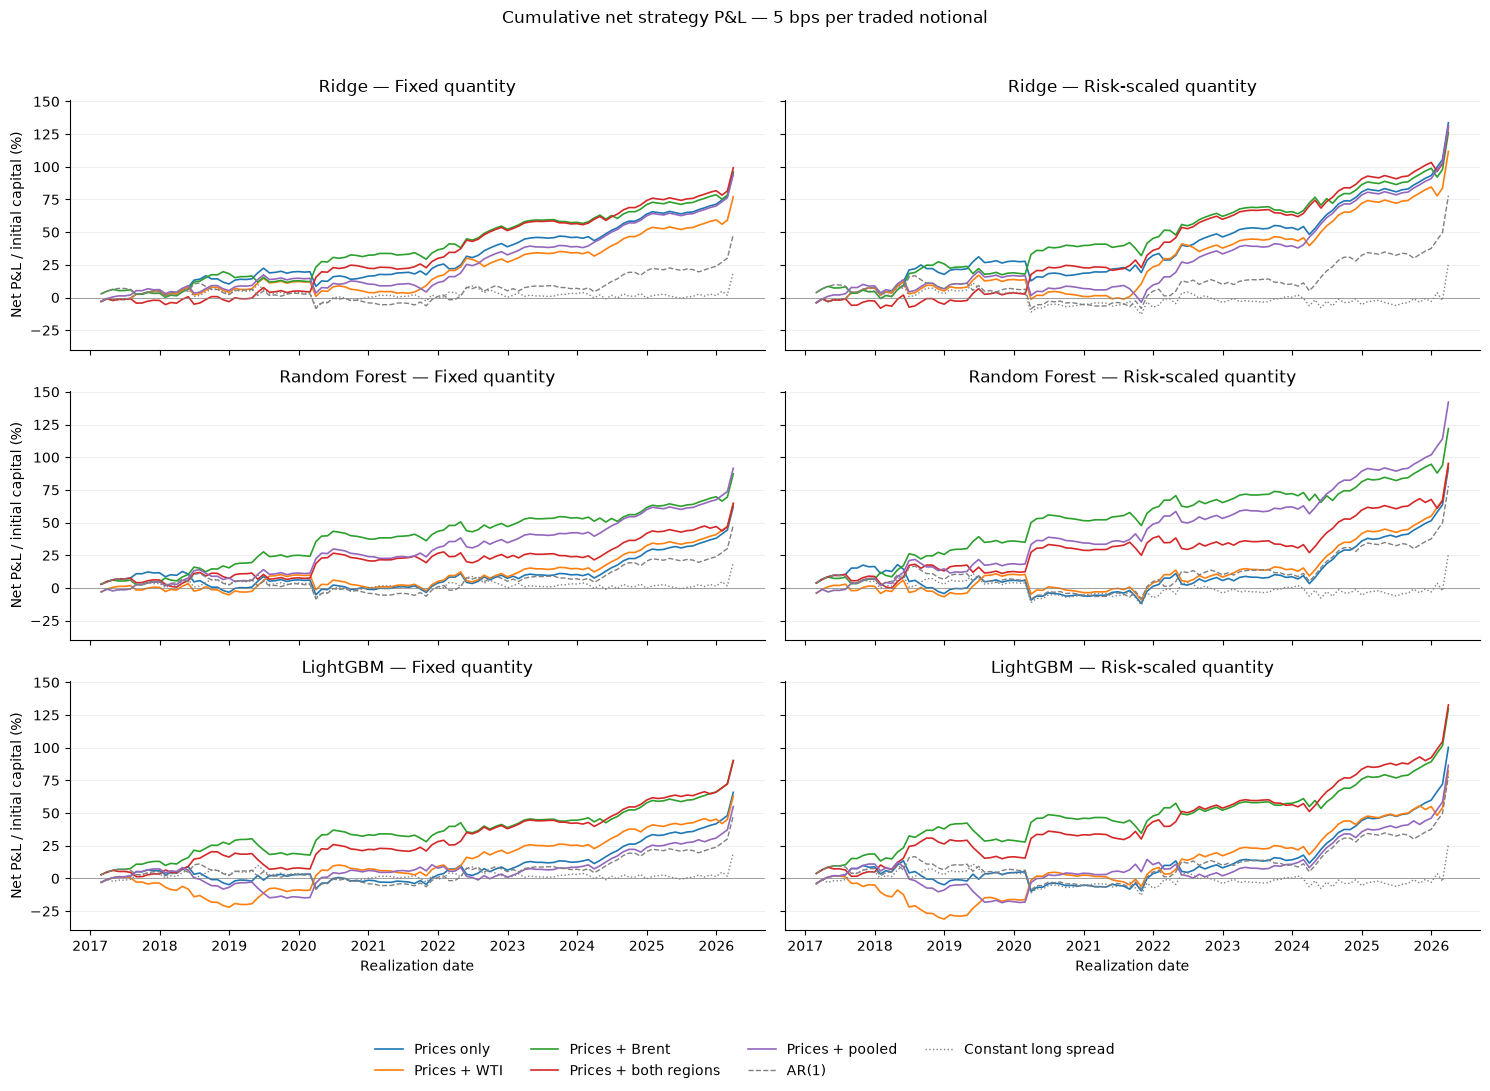

In [48]:
plot_strategy_performance(
    strategy_backtest,
    cost_bps=MAIN_COST_BPS,
)

The cumulative paths show that some fundamental-based strategies separate from their prices-only references before the final large movements. The Brent-related Random Forest strategy builds an advantage in earlier evaluation years, while LightGBM's Brent and combined-region specifications also accumulate gains before 2026.

Nevertheless, sharp movements near the end materially affect several paths and rankings. A high final P&L can combine gradual gains with a small number of influential months. This complements Section 7: fundamentals need not reduce squared errors consistently to alter trading directions profitably, but these historical paths do not establish that the gains will persist.

In [49]:
cost_sensitivity = strategy_performance.pivot(
    index=["model", "feature_set", "sizing"],
    columns="cost_bps",
    values="net_return",
)

cost_sensitivity.columns.name = "Transaction cost (bps)"

display(
    cost_sensitivity.style.format("{:.1%}", na_rep="—")
)

Transaction costs reduce performance but do not eliminate the positive historical results of the selected machine-learning strategies over the tested range.

At ten basis points, fixed-quantity cumulative net P&L remains 93.2% for Ridge with both regional blocks, 81.4% for Random Forest with Brent-related fundamentals, and 82.8% for LightGBM with Brent-related fundamentals. Random Forest with pooled fundamentals achieves 85.2%.

The historical-mean benchmark illustrates the importance of accounting for trading costs. Its fixed-quantity gross gain of 7.6% declines to 5.2% at five basis points, with a break-even cost of 16.06 basis points. Although it remains profitable over the tested range, its performance is substantially weaker than that of the selected machine-learning strategies.

For Ridge with both regions, Random Forest with Brent fundamentals, and LightGBM with Brent fundamentals, fixed-quantity break-even costs are approximately 86, 79, and 66 basis points, respectively. These are ex-post cost budgets for the simulated trading paths, including initial entry and terminal liquidation, rather than estimates of executable market costs.

Overall, selected regional fundamentals improve historical trading performance even though they do not improve point-forecast accuracy. The conclusion remains conditional on the sample, trading assumptions, and simplified transaction-cost model.

## 9. Discussion and conclusion

This project examined whether delayed monthly oil fundamentals improve forecasts of Brent–WTI spread changes and whether they add economic value to a trading strategy. The results highlight an important distinction between statistical forecasting accuracy and trading profitability.

### Forecast accuracy

Past spread dynamics provide a strong forecasting reference. Ridge using four price predictors achieves an RMSE of 2.945 USD/barrel, an MAE of 1.768, and directional accuracy of 70.9%. It also outperforms the zero-change and AR(1) benchmarks in RMSE.

Adding JODI fundamentals does not improve point-forecast accuracy in the current evaluation sample. Every fundamental-augmented specification increases RMSE and MAE relative to its corresponding prices-only model. For Ridge, adding both regional blocks increases RMSE by 3.39%, while the smallest deterioration for LightGBM occurs with Brent-related fundamentals, at 1.77%.

These results suggest that regional oil market information, although economically relevant, does not necessarily improve forecasts of next-month spread changes when incorporated with the assumed publication lag.

### Economic value

The trading results provide a more differentiated conclusion. Under the common sign-based trading rule, selected fundamental specifications improve cumulative net P&L despite having higher forecast errors.

At five basis points and fixed quantities, Ridge with both regional blocks earns cumulative net P&L of 99.3% of initial capital, compared with 95.4% for prices alone. Larger gains arise for Random Forest with Brent-related fundamentals (87.4% versus 62.1%) and LightGBM with Brent-related fundamentals (90.2% versus 65.9%).

Random Forest with pooled fundamentals achieves an even higher cumulative net P&L of 91.6%, illustrating that the geographical aggregation choice affects trading outcomes differently from point-forecast accuracy.

These findings are consistent with the difference between forecasting magnitudes and forecasting directions. A model with higher RMSE may still generate more profitable positions if its directional predictions are better aligned with economically important spread movements.

Risk scaling increases cumulative gains for several specifications, but generally raises realized volatility and does not systematically improve Sharpe ratios. Transaction-cost sensitivity shows that the selected strategies remain profitable over the tested cost range, conditional on the historical simulation.

### Interpretation and limitations

The inventory and physical-flow literature motivates the inclusion of regional oil fundamentals [1, 2], but identifying economic determinants of the spread is different from forecasting its next monthly change. The coefficient and feature-importance analyses describe conditional associations rather than causal effects.

Several limitations qualify the findings. The backtest relies on spot prices rather than executable futures contracts, assumes execution at observed monthly prices, and excludes roll effects, financing, collateral income, and market impact. The fixed reference capital is a normalization convention rather than a futures-margin model.

Country selection uses completeness over the historical sample, which introduces a retrospective selection element. In addition, JODI and FRED may revise previously published observations, so future notebook executions may produce different data vintages and empirical results. Earlier project versions have also examined parts of the evaluation period, meaning the results should be interpreted as retrospective historical evidence rather than a fully untouched test.

Finally, extreme spread movements, particularly near the end of the evaluation period, can materially affect aggregate forecasting and trading performance. The results do not establish that the historical trading gains will persist in live implementation.

### Conclusion

The evidence does not support a systematic improvement in next-month Brent–WTI spread forecasting accuracy from adding delayed JODI fundamentals. Price-based predictors remain the strongest statistical reference across the tested models.

However, selected fundamental specifications improve historical trading profitability under the specified sign-based strategy. The economic value of fundamentals therefore depends on the forecasting model, geographical aggregation, and evaluation objective.

The central conclusion is that **better point forecasts and better trading decisions are not necessarily the same thing**. Oil fundamentals may provide useful directional information even when they fail to reduce conventional forecasting errors.

## References

[1] Geyer-Klingeberg, J., & Rathgeber, A. W. (2021). *Determinants of the WTI–Brent price spread revisited*. Journal of Futures Markets, 41(5), 736–757. [https://doi.org/10.1002/fut.22184](https://doi.org/10.1002/fut.22184).

[2] Sifat, I., Zarei, A., & Ah Mand, A. (2023). *Revisiting WTI–Brent spread and its drivers*. Energy Strategy Reviews, 50, 101206. [https://doi.org/10.1016/j.esr.2023.101206](https://doi.org/10.1016/j.esr.2023.101206).

[3] U.S. Energy Information Administration. (2015). *Effects of Removing Restrictions on U.S. Crude Oil Exports*. September 2015, especially pp. 8–10. [Report](https://www.eia.gov/analysis/requests/crude-exports/pdf/fullreport.pdf).

[4] U.S. Government Accountability Office. (2020). *Crude Oil Markets: Effects of the Repeal of the Crude Oil Export Ban*. GAO-21-118. [Report and summary](https://www.gao.gov/products/gao-21-118).

[5] Champonnois, S. (2026). *Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*. Course notes, September 15, 2026. [Associated skfin repository](https://github.com/schampon/skfin). See Chapters 4–7, 14–15, and 20.

**Data sources:** EIA spot price series distributed through FRED, and the JODI Oil database. Source links and selected variables are introduced in Section 2.